In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

drive_root = Path("/content/drive/MyDrive/final_year_project/Tea")

matches = [
    path for path in drive_root.rglob("*")
    if path.is_dir() and path.name.lower() in {
        "tea leaf disease image",
        "tea"
    }
]

print("Possible Tea dataset folders:")
for path in matches[:30]:
    print(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Possible Tea dataset folders:


In [ ]:
from pathlib import Path
import zipfile

project_dir = Path("/content/drive/MyDrive/final_year_project/Tea")

zip_files = list(project_dir.rglob("*.zip"))
print("ZIP files found:")
for path in zip_files:
    print(path)

ZIP files found:
/content/drive/MyDrive/final_year_project/Tea/Tea Leaf Disease Image.zip


In [ ]:
from pathlib import Path
import zipfile

zip_path = Path(
    "/content/drive/MyDrive/final_year_project/Tea/Tea Leaf Disease Image.zip"
)
extract_dir = zip_path.parent / "Tea Leaf Disease Image"

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

print("Extracted to:", extract_dir)
print("Top-level items:")
for item in sorted(extract_dir.iterdir()):
    print(item.name)

Extracted to: /content/drive/MyDrive/final_year_project/Tea/Tea Leaf Disease Image
Top-level items:
Blight
Healthy_Leaf
Helopeltis
Red_Rust


In [ ]:
from pathlib import Path
import shutil
import zipfile

drive_zip = Path(
    "/content/drive/MyDrive/final_year_project/Tea/Tea Leaf Disease Image.zip"
)
local_zip = Path("/content/Tea Leaf Disease Image.zip")
local_extract_dir = Path("/content/tea_raw")

shutil.copy2(drive_zip, local_zip)

with zipfile.ZipFile(local_zip, "r") as archive:
    archive.extractall(local_extract_dir)

print("Extracted in Colab at:", local_extract_dir)
print("Top-level items:")
for item in sorted(local_extract_dir.iterdir()):
    print(item.name)

Extracted in Colab at: /content/tea_raw
Top-level items:
Blight
Healthy_Leaf
Helopeltis
Red_Rust


In [ ]:
from pathlib import Path
from collections import Counter
from PIL import Image, UnidentifiedImageError

DATA_DIR = Path("/content/tea_raw")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

total_images = 0
readable_images = 0
unreadable_images = []
class_counts = {}
size_counts = Counter()

for class_dir in sorted(path for path in DATA_DIR.iterdir() if path.is_dir()):
    image_paths = [
        path for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts[class_dir.name] = len(image_paths)
    total_images += len(image_paths)

    for image_path in image_paths:
        try:
            with Image.open(image_path) as image:
                image.verify()

            with Image.open(image_path) as image:
                size_counts[image.size] += 1

            readable_images += 1

        except (UnidentifiedImageError, OSError, ValueError):
            unreadable_images.append(str(image_path))

print("Image counts by class:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

print(f"\nTotal image files: {total_images}")
print(f"Readable images: {readable_images}")
print(f"Unreadable images: {len(unreadable_images)}")

print("\nMost common image sizes:")
for size, count in size_counts.most_common(10):
    print(f"{size}: {count}")

if unreadable_images:
    print("\nFirst unreadable files:")
    for path in unreadable_images[:20]:
        print(path)

Image counts by class:
Blight: 555
Healthy_Leaf: 650
Helopeltis: 675
Red_Rust: 620

Total image files: 2500
Readable images: 2500
Unreadable images: 0

Most common image sizes:
(3024, 4032): 2146
(3456, 4608): 192
(3072, 4096): 71
(4608, 3456): 41
(4032, 3024): 39
(4096, 3072): 9
(1200, 1600): 2


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd
from tqdm.auto import tqdm

DATA_DIR = Path("/content/tea_raw")
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

records = []

for class_dir in sorted(path for path in DATA_DIR.iterdir() if path.is_dir()):
    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "image_path": str(image_path),
                "label": class_dir.name,
            })

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

hashes = []
for record in tqdm(records, desc="Checking exact duplicates"):
    hashes.append(sha256_file(record["image_path"]))

df = pd.DataFrame(records)
df["sha256"] = hashes

duplicate_rows = df[df.duplicated("sha256", keep=False)].copy()
duplicate_groups = []

for image_hash, group in duplicate_rows.groupby("sha256"):
    labels = sorted(group["label"].unique())
    duplicate_groups.append({
        "sha256": image_hash,
        "labels": ", ".join(labels),
        "label_conflict": len(labels) > 1,
        "copies": len(group),
        "image_paths": " | ".join(group["image_path"]),
    })

duplicate_report = pd.DataFrame(duplicate_groups)
duplicate_report.to_csv(OUTPUT_DIR / "exact_duplicate_report.csv", index=False)

if not duplicate_report.empty:
    conflicts = duplicate_report[duplicate_report["label_conflict"]]
else:
    conflicts = duplicate_report

print("Images checked:", len(df))
print("Duplicate groups:", len(duplicate_report))
print("Groups with conflicting labels:", len(conflicts))
print("Groups with one consistent label:", len(duplicate_report) - len(conflicts))
print("Report saved to:", OUTPUT_DIR / "exact_duplicate_report.csv")

if not conflicts.empty:
    print("\nConflicting-label duplicate groups:")
    display(conflicts[["labels", "copies", "image_paths"]])

Checking exact duplicates:   0%|          | 0/2500 [00:00<?, ?it/s]

Images checked: 2500
Duplicate groups: 632
Groups with conflicting labels: 2
Groups with one consistent label: 630
Report saved to: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/exact_duplicate_report.csv

Conflicting-label duplicate groups:


,labels,copies,image_paths
436,"Blight, Helopeltis",2,/content/tea_raw/Blight/Gray_Blight_102.jpg | ...
494,"Helopeltis, Red_Rust",2,/content/tea_raw/Helopeltis/Helopeltis_478.jpg...


In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

# df and duplicate_report come from the exact-duplicate check cell.
conflicting_hashes = set(
    duplicate_report.loc[
        duplicate_report["label_conflict"], "sha256"
    ]
)

# Remove both copies of cross-label conflicts.
clean_df = df[~df["sha256"].isin(conflicting_hashes)].copy()

# For remaining exact duplicates, keep one copy per hash.
clean_df = clean_df.drop_duplicates(subset="sha256", keep="first")
clean_df = clean_df.reset_index(drop=True)

manifest_path = OUTPUT_DIR / "tea_clean_manifest.csv"
clean_df[["image_path", "label", "sha256"]].to_csv(manifest_path, index=False)

print("Images before duplicate cleanup:", len(df))
print("Conflicting-label images removed:", int(df["sha256"].isin(conflicting_hashes).sum()))
print("Consistent duplicate copies removed:", len(df) - int(df["sha256"].isin(conflicting_hashes).sum()) - len(clean_df))
print("Images in cleaned manifest:", len(clean_df))
print("\nImages per class after cleanup:")
print(clean_df["label"].value_counts().sort_index())
print("\nSaved manifest:", manifest_path)

Images before duplicate cleanup: 2500
Conflicting-label images removed: 4
Consistent duplicate copies removed: 786
Images in cleaned manifest: 1710

Images per class after cleanup:
label
Blight          376
Healthy_Leaf    412
Helopeltis      460
Red_Rust        462
Name: count, dtype: int64

Saved manifest: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_clean_manifest.csv


In [ ]:
!pip -q install ImageHash

from pathlib import Path
import re
import numpy as np
import pandas as pd
import imagehash
from PIL import Image, ImageOps
from tqdm.auto import tqdm

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
manifest_path = OUTPUT_DIR / "tea_clean_manifest.csv"
clean_df = pd.read_csv(manifest_path)

# Raise this to find looser visual matches; lower it for stricter matches.
HAMMING_DISTANCE_LIMIT = 8

def orientation_robust_phash(image_path):
    with Image.open(image_path) as opened:
        image = ImageOps.exif_transpose(opened).convert("RGB")

    views = [
        image,
        ImageOps.mirror(image),
        ImageOps.flip(image),
        ImageOps.mirror(ImageOps.flip(image)),
        image.rotate(90, expand=True),
        image.rotate(180, expand=True),
        image.rotate(270, expand=True),
        ImageOps.mirror(image.rotate(90, expand=True)),
    ]

    # Keep a canonical hash across common flip and rotation augmentations.
    return min(int(str(imagehash.phash(view)), 16) for view in views)

hash_values = []
hash_errors = []

for row in tqdm(clean_df.itertuples(index=False), total=len(clean_df),
                desc="Computing orientation-robust perceptual hashes"):
    try:
        hash_values.append(orientation_robust_phash(row.image_path))
    except Exception as exc:
        hash_values.append(None)
        hash_errors.append((row.image_path, str(exc)))

valid_indices = [i for i, value in enumerate(hash_values) if value is not None]
valid_hashes = np.array([hash_values[i] for i in valid_indices], dtype=np.uint64)

# Vectorized 64-bit Hamming distances.
byte_lookup = np.array([n.bit_count() for n in range(256)], dtype=np.uint8)
xor_matrix = valid_hashes[:, None] ^ valid_hashes[None, :]
distance_matrix = np.zeros(xor_matrix.shape, dtype=np.uint8)

for shift in range(0, 64, 8):
    byte_values = ((xor_matrix >> shift) & 255).astype(np.uint8)
    distance_matrix += byte_lookup[byte_values]

candidate_pairs = []
for left in range(len(valid_indices)):
    for right in range(left + 1, len(valid_indices)):
        distance = int(distance_matrix[left, right])
        if distance <= HAMMING_DISTANCE_LIMIT:
            i = valid_indices[left]
            j = valid_indices[right]
            row_a = clean_df.iloc[i]
            row_b = clean_df.iloc[j]
            candidate_pairs.append({
                "image_path_1": row_a["image_path"],
                "label_1": row_a["label"],
                "image_path_2": row_b["image_path"],
                "label_2": row_b["label"],
                "hamming_distance": distance,
                "different_labels": row_a["label"] != row_b["label"],
            })

near_df = pd.DataFrame(candidate_pairs).sort_values(
    "hamming_distance"
) if candidate_pairs else pd.DataFrame(columns=[
    "image_path_1", "label_1", "image_path_2", "label_2",
    "hamming_distance", "different_labels"
])

near_path = OUTPUT_DIR / "near_duplicate_candidates.csv"
near_df.to_csv(near_path, index=False)

# Also flag augmentation-like names, even if the perceptual hash missed them.
augmentation_pattern = re.compile(
    r"(^|[_\-\s])(aug|augmented|flip|flipped|rotate|rotated|"
    r"rotation|crop|cropped|transformed|edited|copy)([_\-\s0-9.]|$)",
    re.IGNORECASE,
)
clean_df["augmentation_like_filename"] = clean_df["image_path"].apply(
    lambda value: bool(augmentation_pattern.search(Path(value).name))
)
name_flags = clean_df[clean_df["augmentation_like_filename"]].copy()
name_path = OUTPUT_DIR / "augmentation_filename_review.csv"
name_flags.to_csv(name_path, index=False)

print("Images checked:", len(clean_df))
print("Images with perceptual-hash errors:", len(hash_errors))
print("Near-duplicate candidate pairs:", len(near_df))
print("Candidate pairs with different labels:",
      int(near_df["different_labels"].sum()) if len(near_df) else 0)
print("Augmentation-like filenames:", len(name_flags))
print("Near-duplicate report:", near_path)
print("Filename review report:", name_path)

if len(near_df):
    display(near_df.head(30))

if hash_errors:
    print("\nFirst hash errors:")
    for path, error in hash_errors[:10]:
        print(path, "->", error)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 14.6 MB/s eta 0:00:00


Computing orientation-robust perceptual hashes:   0%|          | 0/1710 [00:00<?, ?it/s]

Images checked: 1710
Images with perceptual-hash errors: 0
Near-duplicate candidate pairs: 12
Candidate pairs with different labels: 0
Augmentation-like filenames: 0
Near-duplicate report: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/near_duplicate_candidates.csv
Filename review report: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/augmentation_filename_review.csv


,image_path_1,label_1,image_path_2,label_2,hamming_distance,different_labels
10,/content/tea_raw/Helopeltis/Helopeltis_515.jpg,Helopeltis,/content/tea_raw/Helopeltis/Helopeltis_554.jpg,Helopeltis,0,False
1,/content/tea_raw/Blight/Brown_Blight_102.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_101.jpg,Blight,2,False
7,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_134...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_138...,Healthy_Leaf,2,False
5,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_294...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_156...,Healthy_Leaf,2,False
9,/content/tea_raw/Helopeltis/Helopeltis_45.jpg,Helopeltis,/content/tea_raw/Helopeltis/Helopeltis_182.jpg,Helopeltis,2,False
4,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_168...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_166...,Healthy_Leaf,4,False
6,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_294...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_154...,Healthy_Leaf,4,False
3,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_306...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_178...,Healthy_Leaf,6,False
8,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_156...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_154...,Healthy_Leaf,6,False
2,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_98.jpg,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_100...,Healthy_Leaf,8,False


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
near_df = pd.read_csv(OUTPUT_DIR / "near_duplicate_candidates.csv")

for start in range(0, len(near_df), 4):
    batch = near_df.iloc[start:start + 4]

    fig, axes = plt.subplots(len(batch), 2, figsize=(12, 4 * len(batch)))
    if len(batch) == 1:
        axes = [axes]

    for row_number, (_, row) in enumerate(batch.iterrows()):
        for column, path_column in enumerate(["image_path_1", "image_path_2"]):
            image_path = row[path_column]

            with Image.open(image_path) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                image.thumbnail((500, 350))
                axes[row_number][column].imshow(image)

            label_column = "label_1" if column == 0 else "label_2"
            axes[row_number][column].set_title(
                f"Pair {row.name} | {row[label_column]}\n"
                f"{Path(image_path).name}"
            )
            axes[row_number][column].axis("off")

        print(
            f"Pair {row.name}: Hamming distance={row['hamming_distance']}, "
            f"{row['image_path_1']}  <->  {row['image_path_2']}"
        )

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

# Use the 12 pairs already visually confirmed as duplicates.
confirmed_pairs = pd.read_csv(OUTPUT_DIR / "near_duplicate_candidates.csv")

duplicate_paths = set(confirmed_pairs["image_path_1"])
duplicate_paths.update(confirmed_pairs["image_path_2"])

# Remove every confirmed duplicate image from the clean manifest.
before_count = len(clean_df)
duplicate_images = clean_df[
    clean_df["image_path"].isin(duplicate_paths)
].copy()

tea_df = clean_df[
    ~clean_df["image_path"].isin(duplicate_paths)
].copy().reset_index(drop=True)

# Save both the excluded-image list and the revised manifest.
duplicate_images.to_csv(
    OUTPUT_DIR / "confirmed_near_duplicate_images_set_aside.csv",
    index=False,
)
manifest_path = OUTPUT_DIR / "tea_manifest_after_near_duplicate_removal.csv"
tea_df.to_csv(manifest_path, index=False)

print("Images before setting duplicates aside:", before_count)
print("Confirmed duplicate images set aside:", len(duplicate_images))
print("Images remaining:", len(tea_df))
print("\nRemaining images per class:")
print(tea_df["label"].value_counts().sort_index())
print("\nExcluded-image list:")
print(OUTPUT_DIR / "confirmed_near_duplicate_images_set_aside.csv")
print("Updated manifest:")
print(manifest_path)

Images before setting duplicates aside: 1710
Confirmed duplicate images set aside: 21
Images remaining: 1689

Remaining images per class:
label
Blight          372
Healthy_Leaf    401
Helopeltis      456
Red_Rust        460
Name: count, dtype: int64

Excluded-image list:
/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/confirmed_near_duplicate_images_set_aside.csv
Updated manifest:
/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_manifest_after_near_duplicate_removal.csv


In [ ]:
# Reuse hash_values and valid_indices from the previous near-duplicate cell.
# This expands the candidate cutoff to Hamming distance 12.

HAMMING_DISTANCE_LIMIT = 12

byte_lookup = np.array([n.bit_count() for n in range(256)], dtype=np.uint8)
valid_hashes = np.array(
    [hash_values[i] for i in valid_indices],
    dtype=np.uint64,
)

xor_matrix = valid_hashes[:, None] ^ valid_hashes[None, :]
distance_matrix = np.zeros(xor_matrix.shape, dtype=np.uint8)

for shift in range(0, 64, 8):
    byte_values = ((xor_matrix >> shift) & 255).astype(np.uint8)
    distance_matrix += byte_lookup[byte_values]

candidate_pairs = []

for left in range(len(valid_indices)):
    for right in range(left + 1, len(valid_indices)):
        distance = int(distance_matrix[left, right])

        if distance <= HAMMING_DISTANCE_LIMIT:
            i = valid_indices[left]
            j = valid_indices[right]
            row_a = clean_df.iloc[i]
            row_b = clean_df.iloc[j]

            candidate_pairs.append({
                "image_path_1": row_a["image_path"],
                "label_1": row_a["label"],
                "image_path_2": row_b["image_path"],
                "label_2": row_b["label"],
                "hamming_distance": distance,
                "different_labels": row_a["label"] != row_b["label"],
            })

near_df_12 = pd.DataFrame(candidate_pairs).sort_values(
    "hamming_distance"
)

near_path_12 = OUTPUT_DIR / "near_duplicate_candidates_hamming12.csv"
near_df_12.to_csv(near_path_12, index=False)

print("Images checked:", len(valid_indices))
print("Candidate pairs at distance <= 12:", len(near_df_12))
print(
    "Pairs with different labels:",
    int(near_df_12["different_labels"].sum()),
)
print("Saved:", near_path_12)

display(near_df_12)

Images checked: 1710
Candidate pairs at distance <= 12: 47
Pairs with different labels: 7
Saved: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/near_duplicate_candidates_hamming12.csv


,image_path_1,label_1,image_path_2,label_2,hamming_distance,different_labels
40,/content/tea_raw/Helopeltis/Helopeltis_515.jpg,Helopeltis,/content/tea_raw/Helopeltis/Helopeltis_554.jpg,Helopeltis,0,False
31,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_294...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_156...,Healthy_Leaf,2,False
35,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_134...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_138...,Healthy_Leaf,2,False
16,/content/tea_raw/Blight/Brown_Blight_102.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_101.jpg,Blight,2,False
39,/content/tea_raw/Helopeltis/Helopeltis_45.jpg,Helopeltis,/content/tea_raw/Helopeltis/Helopeltis_182.jpg,Helopeltis,2,False
32,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_294...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_154...,Healthy_Leaf,4,False
30,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_168...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_166...,Healthy_Leaf,4,False
28,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_306...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_178...,Healthy_Leaf,6,False
38,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_156...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_154...,Healthy_Leaf,6,False
3,/content/tea_raw/Blight/Brown_Blight_254.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_1.jpg,Blight,8,False


In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

# Start from the original manifest after exact-dedup cleanup.
base_df = pd.read_csv(OUTPUT_DIR / "tea_clean_manifest.csv")

# These are the 12 candidate pairs from the earlier, stricter scan that
# you reviewed as duplicates.
confirmed_pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_candidates.csv"
)
confirmed_paths = set(confirmed_pairs["image_path_1"])
confirmed_paths.update(confirmed_pairs["image_path_2"])

# Set aside those images; leave the originals on disk.
set_aside_df = base_df[base_df["image_path"].isin(confirmed_paths)].copy()
remaining_df = base_df[~base_df["image_path"].isin(confirmed_paths)].copy()
remaining_df = remaining_df.reset_index(drop=True)

set_aside_df.to_csv(
    OUTPUT_DIR / "confirmed_near_duplicate_images_set_aside.csv",
    index=False,
)

remaining_manifest = OUTPUT_DIR / "tea_manifest_after_confirmed_duplicates.csv"
remaining_df.to_csv(remaining_manifest, index=False)

# Keep the wider-distance pairs only when both images remain in the manifest.
wide_pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_candidates_hamming12.csv"
)
remaining_paths = set(remaining_df["image_path"])

review_pairs = wide_pairs[
    (wide_pairs["hamming_distance"] > 8)
    & wide_pairs["image_path_1"].isin(remaining_paths)
    & wide_pairs["image_path_2"].isin(remaining_paths)
].copy()

review_path = OUTPUT_DIR / "near_duplicate_review_distance_9_to_12.csv"
review_pairs.to_csv(review_path, index=False)

print("Starting cleaned images:", len(base_df))
print("Confirmed duplicate images set aside:", len(set_aside_df))
print("Images remaining:", len(remaining_df))
print("\nRemaining images by class:")
print(remaining_df["label"].value_counts().sort_index())

print("\nDistance 9–12 candidate pairs for review:", len(review_pairs))
print("Cross-label pairs among them:",
      int(review_pairs["different_labels"].sum()))
print("Saved remaining manifest:", remaining_manifest)
print("Saved review pairs:", review_path)

if len(review_pairs):
    display(review_pairs.sort_values("hamming_distance"))

Starting cleaned images: 1710
Confirmed duplicate images set aside: 21
Images remaining: 1689

Remaining images by class:
label
Blight          372
Healthy_Leaf    401
Helopeltis      456
Red_Rust        460
Name: count, dtype: int64

Distance 9–12 candidate pairs for review: 33
Cross-label pairs among them: 7
Saved remaining manifest: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_manifest_after_confirmed_duplicates.csv
Saved review pairs: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/near_duplicate_review_distance_9_to_12.csv


,image_path_1,label_1,image_path_2,label_2,hamming_distance,different_labels
12,/content/tea_raw/Blight/Gray_Blight_129.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_97.jpg,Blight,10,False
13,/content/tea_raw/Blight/Brown_Blight_247.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_240.jpg,Blight,10,False
14,/content/tea_raw/Blight/Gray_Blight_127.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_91.jpg,Blight,10,False
15,/content/tea_raw/Blight/Gray_Blight_115.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_123.jpg,Blight,10,False
16,/content/tea_raw/Red_Rust/Red_Rust_489.jpg,Red_Rust,/content/tea_raw/Red_Rust/Red_Rust_488.jpg,Red_Rust,10,False
17,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_198...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_196...,Healthy_Leaf,10,False
18,/content/tea_raw/Blight/Brown_Blight_247.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_129.jpg,Blight,10,False
19,/content/tea_raw/Blight/Brown_Blight_40.jpg,Blight,/content/tea_raw/Red_Rust/Red_Rust_390.jpg,Red_Rust,10,True
20,/content/tea_raw/Blight/Brown_Blight_398.jpg,Blight,/content/tea_raw/Red_Rust/Red_Rust_149.jpg,Red_Rust,10,True
21,/content/tea_raw/Blight/Brown_Blight_178.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_184.jpg,Blight,10,False


In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

# Start from the original manifest after exact-dedup cleanup.
base_df = pd.read_csv(OUTPUT_DIR / "tea_clean_manifest.csv")

# These are the 12 candidate pairs from the earlier, stricter scan that
# you reviewed as duplicates.
confirmed_pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_candidates.csv"
)
confirmed_paths = set(confirmed_pairs["image_path_1"])
confirmed_paths.update(confirmed_pairs["image_path_2"])

# Set aside those images; leave the originals on disk.
set_aside_df = base_df[base_df["image_path"].isin(confirmed_paths)].copy()
remaining_df = base_df[~base_df["image_path"].isin(confirmed_paths)].copy()
remaining_df = remaining_df.reset_index(drop=True)

set_aside_df.to_csv(
    OUTPUT_DIR / "confirmed_near_duplicate_images_set_aside.csv",
    index=False,
)

remaining_manifest = OUTPUT_DIR / "tea_manifest_after_confirmed_duplicates.csv"
remaining_df.to_csv(remaining_manifest, index=False)

# Keep the wider-distance pairs only when both images remain in the manifest.
wide_pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_candidates_hamming12.csv"
)
remaining_paths = set(remaining_df["image_path"])

review_pairs = wide_pairs[
    (wide_pairs["hamming_distance"] > 8)
    & wide_pairs["image_path_1"].isin(remaining_paths)
    & wide_pairs["image_path_2"].isin(remaining_paths)
].copy()

review_path = OUTPUT_DIR / "near_duplicate_review_distance_9_to_12.csv"
review_pairs.to_csv(review_path, index=False)

print("Starting cleaned images:", len(base_df))
print("Confirmed duplicate images set aside:", len(set_aside_df))
print("Images remaining:", len(remaining_df))
print("\nRemaining images by class:")
print(remaining_df["label"].value_counts().sort_index())

print("\nDistance 9–12 candidate pairs for review:", len(review_pairs))
print("Cross-label pairs among them:",
      int(review_pairs["different_labels"].sum()))
print("Saved remaining manifest:", remaining_manifest)
print("Saved review pairs:", review_path)

if len(review_pairs):
    display(review_pairs.sort_values("hamming_distance"))

Starting cleaned images: 1710
Confirmed duplicate images set aside: 21
Images remaining: 1689

Remaining images by class:
label
Blight          372
Healthy_Leaf    401
Helopeltis      456
Red_Rust        460
Name: count, dtype: int64

Distance 9–12 candidate pairs for review: 33
Cross-label pairs among them: 7
Saved remaining manifest: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_manifest_after_confirmed_duplicates.csv
Saved review pairs: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/near_duplicate_review_distance_9_to_12.csv


,image_path_1,label_1,image_path_2,label_2,hamming_distance,different_labels
12,/content/tea_raw/Blight/Gray_Blight_129.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_97.jpg,Blight,10,False
13,/content/tea_raw/Blight/Brown_Blight_247.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_240.jpg,Blight,10,False
14,/content/tea_raw/Blight/Gray_Blight_127.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_91.jpg,Blight,10,False
15,/content/tea_raw/Blight/Gray_Blight_115.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_123.jpg,Blight,10,False
16,/content/tea_raw/Red_Rust/Red_Rust_489.jpg,Red_Rust,/content/tea_raw/Red_Rust/Red_Rust_488.jpg,Red_Rust,10,False
17,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_198...,Healthy_Leaf,/content/tea_raw/Healthy_Leaf/Healthy_Leaf_196...,Healthy_Leaf,10,False
18,/content/tea_raw/Blight/Brown_Blight_247.jpg,Blight,/content/tea_raw/Blight/Gray_Blight_129.jpg,Blight,10,False
19,/content/tea_raw/Blight/Brown_Blight_40.jpg,Blight,/content/tea_raw/Red_Rust/Red_Rust_390.jpg,Red_Rust,10,True
20,/content/tea_raw/Blight/Brown_Blight_398.jpg,Blight,/content/tea_raw/Red_Rust/Red_Rust_149.jpg,Red_Rust,10,True
21,/content/tea_raw/Blight/Brown_Blight_178.jpg,Blight,/content/tea_raw/Blight/Brown_Blight_184.jpg,Blight,10,False


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

review_pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_review_distance_9_to_12.csv"
).reset_index(drop=True)

review_pairs.insert(0, "pair_id", range(1, len(review_pairs) + 1))
cross_label_pairs = review_pairs[review_pairs["different_labels"] == True]

print("Cross-label pairs to inspect:", len(cross_label_pairs))

for _, row in cross_label_pairs.iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, path_col, label_col in [
        (axes[0], "image_path_1", "label_1"),
        (axes[1], "image_path_2", "label_2"),
    ]:
        image_path = row[path_col]

        with Image.open(image_path) as opened:
            image = ImageOps.exif_transpose(opened).convert("RGB")
            image.thumbnail((600, 500))
            ax.imshow(image)

        ax.set_title(f"{row[label_col]} — {Path(image_path).name}")
        ax.axis("off")

    fig.suptitle(
        f"Pair {int(row['pair_id'])} | "
        f"pHash distance {int(row['hamming_distance'])}",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()

    print(
        f"Pair {int(row['pair_id'])}: "
        f"{row['image_path_1']}  <->  {row['image_path_2']}"
    )

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

review_pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_review_distance_9_to_12.csv"
).reset_index(drop=True)

review_pairs.insert(0, "pair_id", range(1, len(review_pairs) + 1))
same_label_pairs = review_pairs[review_pairs["different_labels"] == False]

print("Same-label pairs to inspect:", len(same_label_pairs))

for _, row in same_label_pairs.iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, path_col, label_col in [
        (axes[0], "image_path_1", "label_1"),
        (axes[1], "image_path_2", "label_2"),
    ]:
        image_path = row[path_col]

        with Image.open(image_path) as opened:
            image = ImageOps.exif_transpose(opened).convert("RGB")
            image.thumbnail((600, 500))
            ax.imshow(image)

        ax.set_title(f"{row[label_col]} — {Path(image_path).name}")
        ax.axis("off")

    fig.suptitle(
        f"Pair {int(row['pair_id'])} | "
        f"pHash distance {int(row['hamming_distance'])}",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()

    print(f"Pair {int(row['pair_id'])}")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
import re
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

pairs = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_review_distance_9_to_12.csv"
)

# Numbers you mentioned for the Healthy candidates.
healthy_ids_to_check = {"196", "198", "140", "142"}

for row_index, row in pairs.iterrows():
    path_1 = Path(row["image_path_1"])
    path_2 = Path(row["image_path_2"])

    name_1 = path_1.stem
    name_2 = path_2.stem

    # Print the known Red_Rust matches and Healthy filenames containing
    # one of the mentioned numeric IDs.
    is_red_rust_pair = (
        "Red_Rust_488" in name_1 or "Red_Rust_489" in name_1
        or "Red_Rust_12" in name_1 or "Red_Rust_13" in name_1
        or "Red_Rust_488" in name_2 or "Red_Rust_489" in name_2
        or "Red_Rust_12" in name_2 or "Red_Rust_13" in name_2
    )

    healthy_numbers = set(
        re.findall(r"\d+", name_1) + re.findall(r"\d+", name_2)
    )
    is_healthy_match = (
        row["label_1"] == "Healthy_Leaf"
        and row["label_2"] == "Healthy_Leaf"
        and bool(healthy_numbers & healthy_ids_to_check)
    )

    if is_red_rust_pair or is_healthy_match:
        print(
            f"Candidate row {row_index}: "
            f"{name_1} [{row['label_1']}]  <->  "
            f"{name_2} [{row['label_2']}], "
            f"distance={row['hamming_distance']}"
        )

Candidate row 4: Red_Rust_489 [Red_Rust]  <->  Red_Rust_488 [Red_Rust], distance=10
Candidate row 5: Healthy_Leaf_198 [Healthy_Leaf]  <->  Healthy_Leaf_196 [Healthy_Leaf], distance=10
Candidate row 10: Healthy_Leaf_140 [Healthy_Leaf]  <->  Healthy_Leaf_142 [Healthy_Leaf], distance=10
Candidate row 11: Red_Rust_13 [Red_Rust]  <->  Red_Rust_12 [Red_Rust], distance=10


In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

input_manifest = (
    OUTPUT_DIR / "tea_manifest_after_confirmed_duplicates.csv"
)
tea_df = pd.read_csv(input_manifest)

confirmed_duplicate_stems = {
    "Red_Rust_488",
    "Red_Rust_489",
    "Red_Rust_12",
    "Red_Rust_13",
    "Healthy_Leaf_196",
    "Healthy_Leaf_198",
    "Healthy_Leaf_140",
    "Healthy_Leaf_142",
}

tea_df["file_stem"] = tea_df["image_path"].apply(
    lambda path: Path(path).stem
)

set_aside_df = tea_df[
    tea_df["file_stem"].isin(confirmed_duplicate_stems)
].copy()

found_stems = set(set_aside_df["file_stem"])
missing_stems = confirmed_duplicate_stems - found_stems

if missing_stems:
    raise ValueError(
        "These expected duplicate filenames were not found in the manifest: "
        + ", ".join(sorted(missing_stems))
    )

tea_df = tea_df[
    ~tea_df["file_stem"].isin(confirmed_duplicate_stems)
].drop(columns="file_stem").reset_index(drop=True)

set_aside_df = set_aside_df.drop(columns="file_stem")

set_aside_path = (
    OUTPUT_DIR / "additional_confirmed_near_duplicates_set_aside.csv"
)
set_aside_df.to_csv(set_aside_path, index=False)

final_manifest = OUTPUT_DIR / "tea_manifest_after_reviewed_duplicates.csv"
tea_df.to_csv(final_manifest, index=False)

print("Additional duplicate images set aside:", len(set_aside_df))
print("Images remaining:", len(tea_df))
print("\nRemaining images by class:")
print(tea_df["label"].value_counts().sort_index())
print("\nSet-aside list:", set_aside_path)
print("Updated working manifest:", final_manifest)

Additional duplicate images set aside: 8
Images remaining: 1681

Remaining images by class:
label
Blight          372
Healthy_Leaf    397
Helopeltis      456
Red_Rust        456
Name: count, dtype: int64

Set-aside list: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/additional_confirmed_near_duplicates_set_aside.csv
Updated working manifest: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_manifest_after_reviewed_duplicates.csv


In [ ]:
from pathlib import Path
import json
import pandas as pd
from sklearn.model_selection import train_test_split

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

manifest_path = OUTPUT_DIR / "tea_manifest_after_reviewed_duplicates.csv"
tea_df = pd.read_csv(manifest_path)

# First hold out 30%, then divide it equally into validation and test.
train_df, holdout_df = train_test_split(
    tea_df,
    test_size=0.30,
    random_state=42,
    stratify=tea_df["label"],
)

validation_df, test_df = train_test_split(
    holdout_df,
    test_size=0.50,
    random_state=42,
    stratify=holdout_df["label"],
)

splits = {
    "train": train_df.reset_index(drop=True),
    "validation": validation_df.reset_index(drop=True),
    "internal_test": test_df.reset_index(drop=True),
}

for split_name, split_df in splits.items():
    split_df.to_csv(OUTPUT_DIR / f"{split_name}_manifest.csv", index=False)

combined_df = pd.concat(
    [
        split_df.assign(split=split_name)
        for split_name, split_df in splits.items()
    ],
    ignore_index=True,
)
combined_df.to_csv(OUTPUT_DIR / "tea_split_manifest.csv", index=False)

summary = pd.crosstab(combined_df["split"], combined_df["label"])
print("Images per split and class:")
display(summary)

print("\nSplit totals:")
for split_name, split_df in splits.items():
    print(f"{split_name}: {len(split_df)} ({len(split_df) / len(tea_df):.1%})")

config = {
    "dataset": "Tea Leaf Disease Image",
    "classes": sorted(tea_df["label"].unique().tolist()),
    "total_images": len(tea_df),
    "target_split_ratios": {
        "train": 0.70,
        "validation": 0.15,
        "internal_test": 0.15,
    },
    "random_state": 42,
    "stratified_by": "label",
    "duplicate_cleaning_manifest": str(manifest_path),
    "split_counts": {
        name: len(split_df) for name, split_df in splits.items()
    },
}

config_path = OUTPUT_DIR / "experiment_config.json"
with open(config_path, "w") as file:
    json.dump(config, file, indent=2)

print("\nSaved split manifests and config to:", OUTPUT_DIR)

Images per split and class:


label,Blight,Healthy_Leaf,Helopeltis,Red_Rust
split,,,,
internal_test,56,59,69,69
train,260,278,319,319
validation,56,60,68,68



Split totals:
train: 1176 (70.0%)
validation: 252 (15.0%)
internal_test: 253 (15.1%)

Saved split manifests and config to: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment


In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

manifest_paths = {
    "train": OUTPUT_DIR / "train_manifest.csv",
    "validation": OUTPUT_DIR / "validation_manifest.csv",
    "internal_test": OUTPUT_DIR / "internal_test_manifest.csv",
}

split_frames = {}
for split_name, path in manifest_paths.items():
    split_frames[split_name] = pd.read_csv(path)

all_paths = {
    name: set(frame["image_path"])
    for name, frame in split_frames.items()
}

path_overlap = {
    "train_validation": all_paths["train"] & all_paths["validation"],
    "train_internal_test": all_paths["train"] & all_paths["internal_test"],
    "validation_internal_test": all_paths["validation"] & all_paths["internal_test"],
}

print("Path overlap counts:")
for pair, overlap in path_overlap.items():
    print(f"{pair}: {len(overlap)}")

combined = pd.concat(
    [
        frame.assign(split=split_name)
        for split_name, frame in split_frames.items()
    ],
    ignore_index=True,
)

if "sha256" in combined.columns:
    repeated_hashes = combined[
        combined.duplicated("sha256", keep=False)
    ].sort_values("sha256")

    print("\nRepeated SHA-256 hashes across split manifests:",
          repeated_hashes["sha256"].nunique())

    if len(repeated_hashes):
        display(repeated_hashes[["split", "label", "image_path", "sha256"]])
else:
    print("\nNo SHA-256 column found; path overlap was checked.")

missing_paths = [
    image_path
    for image_path in combined["image_path"].unique()
    if not Path(image_path).is_file()
]

print("\nMissing image files:", len(missing_paths))
if missing_paths:
    print("First missing paths:")
    for image_path in missing_paths[:10]:
        print(image_path)

print("\nClass counts by split:")
display(pd.crosstab(combined["split"], combined["label"]))

assert all(len(items) == 0 for items in path_overlap.values()), \
    "Image paths overlap across splits."
assert len(missing_paths) == 0, \
    "Some manifest paths cannot be found in Colab."
if "sha256" in combined.columns:
    assert repeated_hashes.empty, \
        "Exact duplicate images appear across splits."

print("\nSplit integrity audit passed.")

Path overlap counts:
train_validation: 0
train_internal_test: 0
validation_internal_test: 0

Repeated SHA-256 hashes across split manifests: 0

Missing image files: 0

Class counts by split:


label,Blight,Healthy_Leaf,Helopeltis,Red_Rust
split,,,,
internal_test,56,59,69,69
train,260,278,319,319
validation,56,60,68,68



Split integrity audit passed.


In [ ]:
import random
from pathlib import Path

import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps, ImageFilter
from torchvision import transforms
from torchvision.transforms import functional as TF

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

IMAGE_SIZE = 448
TILE_SIZE = 288
TILE_STARTS = (0, IMAGE_SIZE - TILE_SIZE)
BATCH_SIZE = 2
NUM_WORKERS = 0

CLASS_NAMES = ["Blight", "Healthy_Leaf", "Helopeltis", "Red_Rust"]
CLASS_TO_IDX = {name: index for index, name in enumerate(CLASS_NAMES)}

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

color_jitter = transforms.ColorJitter(
    brightness=0.15,
    contrast=0.15,
    saturation=0.10,
    hue=0.02,
)

def to_normalized_tensor(image):
    tensor = TF.to_tensor(image)
    return TF.normalize(tensor, IMAGENET_MEAN, IMAGENET_STD)

def prepare_tea_image(image_path, training=False):
    with Image.open(image_path) as opened:
        image = ImageOps.exif_transpose(opened).convert("RGB")

    if training:
        if random.random() < 0.5:
            image = ImageOps.mirror(image)

        image = image.rotate(
            random.uniform(-12, 12),
            resample=Image.Resampling.BILINEAR,
            fillcolor=(127, 127, 127),
        )
        image = color_jitter(image)

        if random.random() < 0.08:
            image = image.filter(
                ImageFilter.GaussianBlur(
                    radius=random.uniform(0.1, 0.5)
                )
            )

    image = ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(127, 127, 127),
    )

    full_tensor = to_normalized_tensor(image)

    tile_tensors = []
    for top in TILE_STARTS:
        for left in TILE_STARTS:
            tile = image.crop(
                (left, top, left + TILE_SIZE, top + TILE_SIZE)
            )
            tile_tensors.append(to_normalized_tensor(tile))

    return full_tensor, torch.stack(tile_tensors)

class TeaImageDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.training = training

        unknown_labels = set(self.dataframe["label"]) - set(CLASS_TO_IDX)
        if unknown_labels:
            raise ValueError(f"Unexpected labels found: {unknown_labels}")

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        full_image, tile_images = prepare_tea_image(
            row["image_path"],
            training=self.training,
        )
        target = CLASS_TO_IDX[row["label"]]
        return full_image, tile_images, target

train_df = pd.read_csv(OUTPUT_DIR / "train_manifest.csv")
validation_df = pd.read_csv(OUTPUT_DIR / "validation_manifest.csv")
test_df = pd.read_csv(OUTPUT_DIR / "internal_test_manifest.csv")

train_dataset = TeaImageDataset(train_df, training=True)
validation_dataset = TeaImageDataset(validation_df, training=False)
test_dataset = TeaImageDataset(test_df, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

full_batch, tile_batch, label_batch = next(iter(train_loader))

print("Classes:", CLASS_NAMES)
print("Train / validation / internal test:",
      len(train_dataset), len(validation_dataset), len(test_dataset))
print("Full image batch:", tuple(full_batch.shape))
print("Tile batch:", tuple(tile_batch.shape))
print("Label batch:", tuple(label_batch.shape))
print("Example label:", CLASS_NAMES[label_batch[0].item()])
print("GPU available:", torch.cuda.is_available())

Classes: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
Train / validation / internal test: 1176 252 253
Full image batch: (2, 3, 448, 448)
Tile batch: (2, 4, 3, 288, 288)
Label batch: (2,)
Example label: Healthy_Leaf
GPU available: True


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

class SpatialSelfAttention(nn.Module):
    def __init__(self, channels=256, heads=4, attention_size=14):
        super().__init__()
        self.attention_size = attention_size
        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=heads,
            batch_first=True,
        )
        self.norm = nn.LayerNorm(channels)
        self.gate = nn.Conv2d(channels * 2, channels, kernel_size=1)

    def forward(self, feature_map):
        original_size = feature_map.shape[-2:]

        small = F.adaptive_avg_pool2d(
            feature_map,
            (self.attention_size, self.attention_size),
        )
        tokens = small.flatten(2).transpose(1, 2)

        attended, _ = self.attention(
            tokens, tokens, tokens, need_weights=False
        )
        tokens = self.norm(tokens + attended)

        context = tokens.transpose(1, 2).reshape(
            feature_map.shape[0],
            feature_map.shape[1],
            self.attention_size,
            self.attention_size,
        )
        context = F.interpolate(
            context,
            size=original_size,
            mode="bilinear",
            align_corners=False,
        )

        gate = torch.sigmoid(
            self.gate(torch.cat([feature_map, context], dim=1))
        )
        return feature_map + gate * context


class TeaResNet50Attention(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        backbone = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V2
        )
        print("Loaded ImageNet pretrained ResNet50 weights.")

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        fusion_channels = 256
        self.project2 = nn.Conv2d(512, fusion_channels, kernel_size=1)
        self.project3 = nn.Conv2d(1024, fusion_channels, kernel_size=1)
        self.project4 = nn.Conv2d(2048, fusion_channels, kernel_size=1)

        self.fusion = nn.Sequential(
            nn.Conv2d(
                fusion_channels * 3,
                fusion_channels,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(fusion_channels),
            nn.ReLU(inplace=True),
        )

        self.self_attention = SpatialSelfAttention(fusion_channels)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.tile_score = nn.Linear(fusion_channels, 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(fusion_channels * 3),
            nn.Dropout(0.35),
            nn.Linear(fusion_channels * 3, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(512, num_classes),
        )

    def encode_view(self, images):
        x = self.stem(images)
        x = self.layer1(x)

        fine = self.layer2(x)
        middle = self.layer3(fine)
        deep = self.layer4(middle)

        output_size = fine.shape[-2:]
        fine = self.project2(fine)
        middle = F.interpolate(
            self.project3(middle),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )
        deep = F.interpolate(
            self.project4(deep),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )

        fused = self.fusion(torch.cat([fine, middle, deep], dim=1))
        attended = self.self_attention(fused)
        return self.pool(attended).flatten(1)

    def forward(self, full_images, tile_images):
        full_features = self.encode_view(full_images)

        batch_size, tile_count, channels, height, width = tile_images.shape
        flat_tiles = tile_images.reshape(
            batch_size * tile_count, channels, height, width
        )
        tile_features = self.encode_view(flat_tiles).reshape(
            batch_size, tile_count, -1
        )

        tile_weights = torch.softmax(
            self.tile_score(tile_features).squeeze(-1),
            dim=1,
        )
        weighted_tiles = (
            tile_features * tile_weights.unsqueeze(-1)
        ).sum(dim=1)
        strongest_tile = tile_features.max(dim=1).values

        combined = torch.cat(
            [full_features, weighted_tiles, strongest_tile],
            dim=1,
        )
        return self.classifier(combined)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TeaResNet50Attention(num_classes=len(CLASS_NAMES)).to(DEVICE)

# Test one sample to confirm the model output shape and values.
model.eval()
with torch.inference_mode():
    sample_logits = model(
        full_batch[:1].to(DEVICE),
        tile_batch[:1].to(DEVICE),
    )

print("Device:", DEVICE)
print("Output shape:", tuple(sample_logits.shape))
print("Output values are finite:", torch.isfinite(sample_logits).all().item())
print("Trainable parameters:",
      sum(parameter.numel() for parameter in model.parameters()
          if parameter.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 92.8MB/s]


Loaded ImageNet pretrained ResNet50 weights.
Device: cuda
Output shape: (1, 4)
Output values are finite: True
Trainable parameters: 26989125


In [ ]:
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from tqdm.auto import tqdm

CHECKPOINT_DIR = OUTPUT_DIR
LAST_CHECKPOINT = CHECKPOINT_DIR / "tea_last_checkpoint.pth"
BEST_CHECKPOINT = CHECKPOINT_DIR / "tea_best_model.pth"
HISTORY_PATH = CHECKPOINT_DIR / "tea_training_history.csv"

MAX_EPOCHS = 15
ACCUMULATION_STEPS = 4
EARLY_STOPPING_PATIENCE = 5
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4
USE_AMP = DEVICE.type == "cuda"
RESUME_TRAINING = True

# Mild class weights; the classes are not severely imbalanced.
class_counts = train_df["label"].value_counts()
class_weights = torch.tensor(
    [
        (class_counts.max() / class_counts[class_name]) ** 0.5
        for class_name in CLASS_NAMES
    ],
    dtype=torch.float32,
    device=DEVICE,
)
class_weights = class_weights / class_weights.mean()

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05,
)

backbone_parameters = []
head_parameters = []

for name, parameter in model.named_parameters():
    if not parameter.requires_grad:
        continue

    if name.startswith(("stem.", "layer1.", "layer2.", "layer3.", "layer4.")):
        backbone_parameters.append(parameter)
    else:
        head_parameters.append(parameter)

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": BACKBONE_LR},
        {"params": head_parameters, "lr": HEAD_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

start_epoch = 1
best_val_macro_f1 = 0.0
epochs_without_improvement = 0
history = []

if RESUME_TRAINING and LAST_CHECKPOINT.exists():
    checkpoint = torch.load(
        LAST_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False,
    )

    if checkpoint["class_names"] != CLASS_NAMES:
        raise ValueError(
            "Checkpoint classes do not match the current class order."
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    if checkpoint.get("scaler_state_dict"):
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_macro_f1 = checkpoint["best_val_macro_f1"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    history = checkpoint.get("history", [])

    print(f"Resuming at epoch {start_epoch}")
    print(f"Best validation macro-F1 so far: {best_val_macro_f1:.4f}")
else:
    print("Starting a fresh Tea training run.")

def save_checkpoint(path, state):
    temporary_path = Path(str(path) + ".tmp")
    torch.save(state, temporary_path)
    temporary_path.replace(path)

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_loss_sum = 0.0
    train_targets = []
    train_predictions = []
    total_train_batches = len(train_loader)

    progress = tqdm(
        enumerate(train_loader, start=1),
        total=total_train_batches,
        desc=f"Epoch {epoch}/{MAX_EPOCHS} — training",
    )

    for step, (full_images, tile_images, targets) in progress:
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(full_images, tile_images)
            loss = criterion(logits, targets)

        # Correctly scale the final accumulation window if it is incomplete.
        window_start = ((step - 1) // ACCUMULATION_STEPS) * ACCUMULATION_STEPS
        window_size = min(
            ACCUMULATION_STEPS,
            total_train_batches - window_start,
        )
        scaler.scale(loss / window_size).backward()

        if step % ACCUMULATION_STEPS == 0 or step == total_train_batches:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        batch_size = targets.size(0)
        train_loss_sum += loss.item() * batch_size
        train_targets.extend(targets.detach().cpu().tolist())
        train_predictions.extend(logits.detach().argmax(1).cpu().tolist())

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.1e}",
        )

    train_loss = train_loss_sum / len(train_dataset)
    train_accuracy = accuracy_score(train_targets, train_predictions)
    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    model.eval()
    val_loss_sum = 0.0
    val_targets = []
    val_predictions = []

    with torch.inference_mode():
        for full_images, tile_images, targets in tqdm(
            validation_loader,
            desc=f"Epoch {epoch}/{MAX_EPOCHS} — validation",
        ):
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full_images, tile_images)
                loss = criterion(logits, targets)

            val_loss_sum += loss.item() * targets.size(0)
            val_targets.extend(targets.cpu().tolist())
            val_predictions.extend(logits.argmax(1).cpu().tolist())

    val_loss = val_loss_sum / len(validation_dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_balanced_accuracy = balanced_accuracy_score(
        val_targets, val_predictions
    )
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=list(range(len(CLASS_NAMES))),
        average="macro",
        zero_division=0,
    )

    scheduler.step()

    improved = val_macro_f1 > best_val_macro_f1
    if improved:
        best_val_macro_f1 = val_macro_f1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    epoch_result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_balanced_accuracy": val_balanced_accuracy,
        "val_macro_f1": val_macro_f1,
    }
    history.append(epoch_result)

    print(
        f"\nEpoch {epoch}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Train macro-F1: {train_macro_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.4f} | "
        f"Val balanced accuracy: {val_balanced_accuracy:.4f} | "
        f"Val macro-F1: {val_macro_f1:.4f}"
    )

    checkpoint_state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_macro_f1": best_val_macro_f1,
        "epochs_without_improvement": epochs_without_improvement,
        "class_names": CLASS_NAMES,
        "history": history,
    }
    save_checkpoint(LAST_CHECKPOINT, checkpoint_state)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
    print("Saved latest checkpoint:", LAST_CHECKPOINT)

    if improved:
        best_state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "metrics": epoch_result,
        }
        save_checkpoint(BEST_CHECKPOINT, best_state)
        print("Saved new best model:", BEST_CHECKPOINT)

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping: validation macro-F1 did not improve for "
            f"{EARLY_STOPPING_PATIENCE} consecutive epochs."
        )
        break

print("\nTraining cell finished.")
print("Best validation macro-F1:", round(best_val_macro_f1, 4))
print("Best checkpoint:", BEST_CHECKPOINT)
print("Latest resumable checkpoint:", LAST_CHECKPOINT)
print("Training history:", HISTORY_PATH)

Starting a fresh Tea training run.


Epoch 1/15 — training:   0%|          | 0/588 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm

DATA_DIR = Path("/content/tea_raw")
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
CACHE_DIR = Path("/content/tea_cache_448")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

manifest_files = [
    OUTPUT_DIR / "train_manifest.csv",
    OUTPUT_DIR / "validation_manifest.csv",
    OUTPUT_DIR / "internal_test_manifest.csv",
]
all_images = pd.concat(
    [pd.read_csv(path) for path in manifest_files],
    ignore_index=True,
).drop_duplicates("image_path")

cache_records = []

for row in tqdm(all_images.itertuples(index=False), total=len(all_images),
                desc="Caching resized Tea images"):
    source_path = Path(row.image_path)
    relative_path = source_path.relative_to(DATA_DIR)

    # Keep the original filename in the cache path to avoid collisions.
    cached_path = CACHE_DIR / relative_path.parent / f"{relative_path.name}.jpg"
    cached_path.parent.mkdir(parents=True, exist_ok=True)

    if not cached_path.exists():
        with Image.open(source_path) as opened:
            image = ImageOps.exif_transpose(opened).convert("RGB")
            image = ImageOps.pad(
                image,
                (448, 448),
                method=Image.Resampling.LANCZOS,
                color=(127, 127, 127),
            )
            image.save(cached_path, "JPEG", quality=94, optimize=True)

    cache_records.append({
        "image_path": str(source_path),
        "cached_path": str(cached_path),
        "label": row.label,
    })

cache_manifest = pd.DataFrame(cache_records)
cache_manifest_path = OUTPUT_DIR / "tea_resized_cache_manifest.csv"
cache_manifest.to_csv(cache_manifest_path, index=False)

print("Images cached:", len(cache_manifest))
print("Cache folder:", CACHE_DIR)
print("Cache manifest saved:", cache_manifest_path)

Caching resized Tea images:   0%|          | 0/1681 [00:00<?, ?it/s]

Images cached: 1681
Cache folder: /content/tea_cache_448
Cache manifest saved: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_resized_cache_manifest.csv


In [ ]:
import random
import time
from pathlib import Path

import pandas as pd
import torch
from torch.utils.data import DataLoader
from PIL import Image, ImageOps, ImageFilter
from torchvision import transforms
from torchvision.transforms import functional as TF

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
CACHE_MANIFEST = OUTPUT_DIR / "tea_resized_cache_manifest.csv"

cache_df = pd.read_csv(CACHE_MANIFEST)
CACHE_LOOKUP = dict(zip(cache_df["image_path"], cache_df["cached_path"]))

color_jitter = transforms.ColorJitter(
    brightness=0.15,
    contrast=0.15,
    saturation=0.10,
    hue=0.02,
)

def prepare_tea_image(image_path, training=False):
    image_path = str(image_path)

    if image_path not in CACHE_LOOKUP:
        raise KeyError(f"No cached image found for: {image_path}")

    with Image.open(CACHE_LOOKUP[image_path]) as opened:
        image = opened.convert("RGB")

    if training:
        if random.random() < 0.5:
            image = ImageOps.mirror(image)

        image = image.rotate(
            random.uniform(-12, 12),
            resample=Image.Resampling.BILINEAR,
            fillcolor=(127, 127, 127),
        )
        image = color_jitter(image)

        if random.random() < 0.08:
            image = image.filter(
                ImageFilter.GaussianBlur(
                    radius=random.uniform(0.1, 0.5)
                )
            )

    full_tensor = TF.normalize(
        TF.to_tensor(image),
        IMAGENET_MEAN,
        IMAGENET_STD,
    )

    tile_tensors = []
    for top in TILE_STARTS:
        for left in TILE_STARTS:
            tile = image.crop(
                (left, top, left + TILE_SIZE, top + TILE_SIZE)
            )
            tile_tensor = TF.normalize(
                TF.to_tensor(tile),
                IMAGENET_MEAN,
                IMAGENET_STD,
            )
            tile_tensors.append(tile_tensor)

    return full_tensor, torch.stack(tile_tensors)

# The existing dataset class calls prepare_tea_image, so rebuilding the
# datasets and loaders picks up the cached-image preprocessing.
train_df = pd.read_csv(OUTPUT_DIR / "train_manifest.csv")
validation_df = pd.read_csv(OUTPUT_DIR / "validation_manifest.csv")
test_df = pd.read_csv(OUTPUT_DIR / "internal_test_manifest.csv")

train_dataset = TeaImageDataset(train_df, training=True)
validation_dataset = TeaImageDataset(validation_df, training=False)
test_dataset = TeaImageDataset(test_df, training=False)

BATCH_SIZE = 2
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

start_time = time.perf_counter()
full_batch, tile_batch, label_batch = next(iter(train_loader))
batch_load_seconds = time.perf_counter() - start_time

print("Cache entries:", len(CACHE_LOOKUP))
print("Train / validation / internal test:",
      len(train_dataset), len(validation_dataset), len(test_dataset))
print("Full batch:", tuple(full_batch.shape))
print("Tile batch:", tuple(tile_batch.shape))
print("Label batch:", tuple(label_batch.shape))
print(f"First cached batch load time: {batch_load_seconds:.2f} seconds")

Cache entries: 1681
Train / validation / internal test: 1176 252 253
Full batch: (2, 3, 448, 448)
Tile batch: (2, 4, 3, 288, 288)
Label batch: (2,)
First cached batch load time: 0.09 seconds


In [ ]:
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from tqdm.auto import tqdm

CHECKPOINT_DIR = OUTPUT_DIR
LAST_CHECKPOINT = CHECKPOINT_DIR / "tea_last_checkpoint.pth"
BEST_CHECKPOINT = CHECKPOINT_DIR / "tea_best_model.pth"
HISTORY_PATH = CHECKPOINT_DIR / "tea_training_history.csv"

MAX_EPOCHS = 15
ACCUMULATION_STEPS = 4
PATIENCE = 5
USE_AMP = DEVICE.type == "cuda"
RESUME_TRAINING = False  # Fresh start with cached-image preprocessing

# Start again from ImageNet weights; the interrupted run had no epoch checkpoint.
torch.cuda.empty_cache()
torch.backends.cudnn.benchmark = DEVICE.type == "cuda"
model = TeaResNet50Attention(num_classes=len(CLASS_NAMES)).to(DEVICE)

counts = train_df["label"].value_counts()
class_weights = torch.tensor(
    [(counts.max() / counts[name]) ** 0.5 for name in CLASS_NAMES],
    dtype=torch.float32,
    device=DEVICE,
)
class_weights /= class_weights.mean()

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05,
)

backbone_params, head_params = [], []
for name, parameter in model.named_parameters():
    if name.startswith(("stem.", "layer1.", "layer2.", "layer3.", "layer4.")):
        backbone_params.append(parameter)
    else:
        head_params.append(parameter)

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-5},
        {"params": head_params, "lr": 1e-4},
    ],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=MAX_EPOCHS, eta_min=1e-6
)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

start_epoch = 1
best_val_macro_f1 = 0.0
stale_epochs = 0
history = []

if RESUME_TRAINING and LAST_CHECKPOINT.exists():
    checkpoint = torch.load(
        LAST_CHECKPOINT, map_location=DEVICE, weights_only=False
    )
    if checkpoint["class_names"] != CLASS_NAMES:
        raise ValueError("Checkpoint class order does not match this model.")

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    if checkpoint.get("scaler_state_dict"):
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_macro_f1 = checkpoint["best_val_macro_f1"]
    stale_epochs = checkpoint["stale_epochs"]
    history = checkpoint.get("history", [])
    print(f"Resuming at epoch {start_epoch}")
else:
    print("Starting fresh from ImageNet-pretrained weights.")

def save_checkpoint(path, state):
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(state, temporary_path)
    temporary_path.replace(path)

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    train_loss_sum, train_targets, train_predictions = 0.0, [], []

    progress = tqdm(
        enumerate(train_loader, start=1),
        total=len(train_loader),
        desc=f"Epoch {epoch}/{MAX_EPOCHS} training",
    )

    for step, (full_images, tile_images, targets) in progress:
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(full_images, tile_images)
            loss = criterion(logits, targets)

        window_start = ((step - 1) // ACCUMULATION_STEPS) * ACCUMULATION_STEPS
        window_size = min(
            ACCUMULATION_STEPS,
            len(train_loader) - window_start,
        )
        scaler.scale(loss / window_size).backward()

        if step % ACCUMULATION_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        train_loss_sum += loss.item() * targets.size(0)
        train_targets.extend(targets.detach().cpu().tolist())
        train_predictions.extend(logits.detach().argmax(1).cpu().tolist())
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_sum / len(train_dataset)
    train_accuracy = accuracy_score(train_targets, train_predictions)
    train_f1 = f1_score(
        train_targets, train_predictions, labels=list(range(len(CLASS_NAMES))),
        average="macro", zero_division=0,
    )

    model.eval()
    val_loss_sum, val_targets, val_predictions = 0.0, [], []

    with torch.inference_mode():
        for full_images, tile_images, targets in tqdm(
            validation_loader, desc=f"Epoch {epoch}/{MAX_EPOCHS} validation"
        ):
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full_images, tile_images)
                loss = criterion(logits, targets)

            val_loss_sum += loss.item() * targets.size(0)
            val_targets.extend(targets.cpu().tolist())
            val_predictions.extend(logits.argmax(1).cpu().tolist())

    val_loss = val_loss_sum / len(validation_dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_balanced_accuracy = balanced_accuracy_score(
        val_targets, val_predictions
    )
    val_f1 = f1_score(
        val_targets, val_predictions, labels=list(range(len(CLASS_NAMES))),
        average="macro", zero_division=0,
    )

    scheduler.step()
    improved = val_f1 > best_val_macro_f1
    if improved:
        best_val_macro_f1 = val_f1
        stale_epochs = 0
    else:
        stale_epochs += 1

    result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_balanced_accuracy": val_balanced_accuracy,
        "val_macro_f1": val_f1,
    }
    history.append(result)

    print(
        f"\nEpoch {epoch} | "
        f"Train loss={train_loss:.4f}, accuracy={train_accuracy:.4f}, "
        f"macro-F1={train_f1:.4f} | "
        f"Val loss={val_loss:.4f}, accuracy={val_accuracy:.4f}, "
        f"balanced accuracy={val_balanced_accuracy:.4f}, macro-F1={val_f1:.4f}"
    )

    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_macro_f1": best_val_macro_f1,
        "stale_epochs": stale_epochs,
        "class_names": CLASS_NAMES,
        "history": history,
    }
    save_checkpoint(LAST_CHECKPOINT, state)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
    print("Saved latest checkpoint.")

    if improved:
        save_checkpoint(
            BEST_CHECKPOINT,
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "metrics": result,
            },
        )
        print("Saved new best checkpoint.")

    if stale_epochs >= PATIENCE:
        print(f"Early stopping after {PATIENCE} epochs without improvement.")
        break

print("\nTraining finished.")
print("Best validation macro-F1:", round(best_val_macro_f1, 4))
print("Best checkpoint:", BEST_CHECKPOINT)
print("Latest checkpoint:", LAST_CHECKPOINT)

Loaded ImageNet pretrained ResNet50 weights.
Starting fresh from ImageNet-pretrained weights.


Epoch 1/15 training:   0%|          | 0/588 [00:00<?, ?it/s]

Epoch 1/15 validation:   0%|          | 0/126 [00:00<?, ?it/s]


Epoch 1 | Train loss=1.0438, accuracy=0.5859, macro-F1=0.5844 | Val loss=0.5569, accuracy=0.8810, balanced accuracy=0.8766, macro-F1=0.8770
Saved latest checkpoint.
Saved new best checkpoint.


Epoch 2/15 training:   0%|          | 0/588 [00:00<?, ?it/s]

...

Epoch 10/15 validation:   0%|          | 0/126 [00:00<?, ?it/s]


Epoch 10 | Train loss=0.2595, accuracy=0.9779, macro-F1=0.9778 | Val loss=0.3291, accuracy=0.9405, balanced accuracy=0.9399, macro-F1=0.9396
Saved latest checkpoint.


Epoch 11/15 training:   0%|          | 0/588 [00:00<?, ?it/s]

Epoch 11/15 validation:   0%|          | 0/126 [00:00<?, ?it/s]


Epoch 11 | Train loss=0.2533, accuracy=0.9813, macro-F1=0.9807 | Val loss=0.3689, accuracy=0.9286, balanced accuracy=0.9315, macro-F1=0.9285
Saved latest checkpoint.
Early stopping after 5 epochs without improvement.

Training finished.
Best validation macro-F1: 0.9482
Best checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_best_model.pth
Latest checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_last_checkpoint.pth


In [ ]:
import json
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from tqdm.auto import tqdm

BEST_CHECKPOINT = OUTPUT_DIR / "tea_best_model.pth"

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model = TeaResNet50Attention(num_classes=len(CLASS_NAMES)).to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

y_true, y_pred, confidences = [], [], []

with torch.inference_mode():
    for full_images, tile_images, targets in tqdm(
        test_loader,
        desc="Evaluating Tea internal test set",
    ):
        full_images = full_images.to(DEVICE, non_blocking=True)
        tile_images = tile_images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda",
        ):
            logits = model(full_images, tile_images)

        probabilities = torch.softmax(logits.float(), dim=1)
        batch_confidence, batch_predictions = probabilities.max(dim=1)

        y_true.extend(targets.tolist())
        y_pred.extend(batch_predictions.cpu().tolist())
        confidences.extend(batch_confidence.cpu().tolist())

summary = {
    "best_checkpoint_epoch": int(checkpoint["epoch"]),
    "best_validation_metrics": checkpoint["metrics"],
    "test_images": len(y_true),
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
}

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

print("Best checkpoint epoch:", summary["best_checkpoint_epoch"])
print("Internal test images:", summary["test_images"])
print(f"Accuracy: {summary['accuracy']:.4f}")
print(f"Balanced accuracy: {summary['balanced_accuracy']:.4f}")
print(f"Macro-F1: {report['macro avg']['f1-score']:.4f}")
print("\nPer-class report:")
display(
    pd.DataFrame(report)
    .T.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
)
cm_df = pd.DataFrame(
    cm,
    index=[f"true_{name}" for name in CLASS_NAMES],
    columns=[f"pred_{name}" for name in CLASS_NAMES],
)

test_predictions = test_df.reset_index(drop=True).copy()
test_predictions["true_label"] = [CLASS_NAMES[i] for i in y_true]
test_predictions["predicted_label"] = [CLASS_NAMES[i] for i in y_pred]
test_predictions["confidence"] = confidences
test_predictions["correct"] = test_predictions["true_label"] == test_predictions["predicted_label"]

metrics_path = OUTPUT_DIR / "tea_internal_test_metrics.json"
confusion_path = OUTPUT_DIR / "tea_internal_test_confusion_matrix.csv"
predictions_path = OUTPUT_DIR / "tea_internal_test_predictions.csv"

with open(metrics_path, "w") as file:
    json.dump(
        {
            "summary": summary,
            "classification_report": report,
            "confusion_matrix": cm.tolist(),
            "class_names": CLASS_NAMES,
        },
        file,
        indent=2,
    )

cm_df.to_csv(confusion_path)
test_predictions.to_csv(predictions_path, index=False)

print("\nSaved metrics:", metrics_path)
print("Saved confusion matrix:", confusion_path)
print("Saved per-image predictions:", predictions_path)
print("Incorrect predictions:", int((~test_predictions["correct"]).sum()))

Loaded ImageNet pretrained ResNet50 weights.


Evaluating Tea internal test set:   0%|          | 0/127 [00:00<?, ?it/s]

Best checkpoint epoch: 6
Internal test images: 253
Accuracy: 0.9328
Balanced accuracy: 0.9342
Macro-F1: 0.9319

Per-class report:


,precision,recall,f1-score,support
Blight,0.894737,0.910714,0.902655,56.0
Healthy_Leaf,0.907692,1.000000,0.951613,59.0
Helopeltis,0.984848,0.942029,0.962963,69.0
Red_Rust,0.938462,0.884058,0.910448,69.0



Saved metrics: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_internal_test_metrics.json
Saved confusion matrix: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_internal_test_confusion_matrix.csv
Saved per-image predictions: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_internal_test_predictions.csv
Incorrect predictions: 17


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)

predictions_path = OUTPUT_DIR / "tea_internal_test_predictions.csv"
confusion_path = OUTPUT_DIR / "tea_internal_test_confusion_matrix.csv"

test_predictions = pd.read_csv(predictions_path)
confusion_df = pd.read_csv(confusion_path, index_col=0)

print("Confusion matrix (rows = true class, columns = predicted class):")
display(confusion_df)

errors = test_predictions[
    test_predictions["correct"] == False
].reset_index(drop=True)

print(f"\nMisclassified test images: {len(errors)}")

for start in range(0, len(errors), 4):
    batch = errors.iloc[start:start + 4]
    fig, axes = plt.subplots(len(batch), 1, figsize=(8, 4 * len(batch)))

    if len(batch) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, batch.iterrows()):
        image_path = row["image_path"]

        with Image.open(image_path) as opened:
            image = ImageOps.exif_transpose(opened).convert("RGB")
            image.thumbnail((700, 500))
            ax.imshow(image)

        ax.set_title(
            f"True: {row['true_label']} | "
            f"Predicted: {row['predicted_label']} | "
            f"Confidence: {row['confidence']:.3f}\n"
            f"{Path(image_path).name}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

Loaded ImageNet pretrained ResNet50 weights.


Evaluating train:   0%|          | 0/588 [00:00<?, ?it/s]


TRAIN — 1176 images
Accuracy:          0.9592
Balanced accuracy: 0.9594
Macro precision:   0.9582
Macro recall:      0.9594
Macro-F1:          0.9586
Weighted F1:       0.9591

Per-class precision, recall, F1, and support:


,precision,recall,f1-score,support
Blight,0.942085,0.938462,0.940270,260.0
Healthy_Leaf,0.948630,0.996403,0.971930,278.0
Helopeltis,0.990446,0.974922,0.982622,319.0
Red_Rust,0.951768,0.927900,0.939683,319.0


Confusion matrix (rows=true, columns=predicted):


...

Confusion matrix (rows=true, columns=predicted):


,pred_Blight,pred_Healthy_Leaf,pred_Helopeltis,pred_Red_Rust
true_Blight,51,1,0,4
true_Healthy_Leaf,0,59,0,0
true_Helopeltis,2,2,65,0
true_Red_Rust,4,3,1,61



EPOCH-BY-EPOCH TRAINING AND VALIDATION HISTORY


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1
0,1,1.0438,0.5859,0.5844,0.5569,0.8810,0.8766,0.8770
1,2,0.7333,0.7491,0.7455,0.4899,0.8532,0.8583,0.8502
2,3,0.5397,0.8435,0.8396,0.3972,0.9087,0.9079,0.9072
3,4,0.4093,0.9124,0.9107,0.3768,0.9325,0.9302,0.9315
4,5,0.3755,0.9303,0.9293,0.4179,0.9246,0.9262,0.9254
5,6,0.3537,0.9345,0.9333,0.3633,0.9484,0.9506,0.9482
6,7,0.2917,0.9668,0.9665,0.3581,0.9365,0.9383,0.9365
7,8,0.2889,0.9668,0.9663,0.3678,0.9365,0.9388,0.9365
8,9,0.2857,0.9694,0.9688,0.3941,0.9246,0.9254,0.9247
9,10,0.2595,0.9779,0.9778,0.3291,0.9405,0.9399,0.9396



Selected best checkpoint epoch: 6
Best-checkpoint validation metrics: {'epoch': 6, 'train_loss': 0.35370146341267084, 'train_accuracy': 0.9345238095238095, 'train_macro_f1': 0.9332591473282192, 'val_loss': 0.3633226371473736, 'val_accuracy': 0.9484126984126984, 'val_balanced_accuracy': np.float64(0.9506302521008403), 'val_macro_f1': 0.9481814905155866}


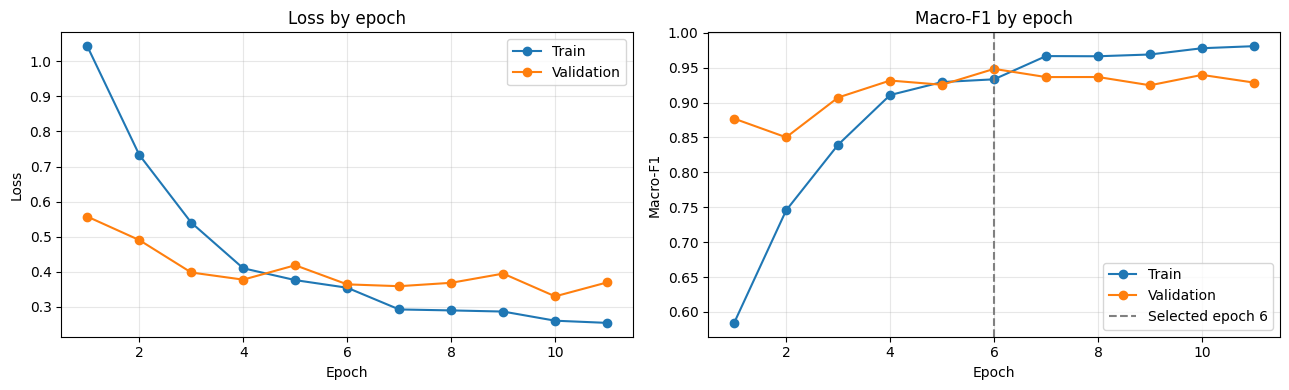


Saved evaluation summary: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_final_evaluation_summary.csv
Saved combined report: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_final_evaluation_report.json
Saved training curves: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_training_validation_curves.png


In [ ]:
import json
from pathlib import Path

import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from tqdm.auto import tqdm

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
BEST_CHECKPOINT = OUTPUT_DIR / "tea_best_model.pth"
HISTORY_PATH = OUTPUT_DIR / "tea_training_history.csv"

# Load the best validation macro-F1 checkpoint.
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)
if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model = TeaResNet50Attention(num_classes=len(CLASS_NAMES)).to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

# Evaluate training images without random training augmentation.
train_eval_dataset = TeaImageDataset(train_df, training=False)
train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

evaluation_loaders = {
    "train": train_eval_loader,
    "validation": validation_loader,
    "internal_test": test_loader,
}

all_reports = {}
all_confusion_matrices = {}
summary_rows = []

def evaluate_split(split_name, loader):
    y_true, y_pred = [], []

    with torch.inference_mode():
        for full_images, tile_images, targets in tqdm(
            loader, desc=f"Evaluating {split_name}"
        ):
            full_images = full_images.to(DEVICE, non_blocking=True)
            tile_images = tile_images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda",
            ):
                logits = model(full_images, tile_images)

            predictions = logits.argmax(dim=1)
            y_true.extend(targets.tolist())
            y_pred.extend(predictions.cpu().tolist())

    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
    )

    metrics = {
        "split": split_name,
        "images": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": report["macro avg"]["precision"],
        "macro_recall": report["macro avg"]["recall"],
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
    }

    report_df = pd.DataFrame(report).T
    report_df.to_csv(
        OUTPUT_DIR / f"tea_{split_name}_classification_report.csv"
    )

    matrix_df = pd.DataFrame(
        matrix,
        index=[f"true_{name}" for name in CLASS_NAMES],
        columns=[f"pred_{name}" for name in CLASS_NAMES],
    )
    matrix_df.to_csv(
        OUTPUT_DIR / f"tea_{split_name}_confusion_matrix.csv"
    )

    all_reports[split_name] = report
    all_confusion_matrices[split_name] = matrix.tolist()
    summary_rows.append(metrics)

    print(f"\n{split_name.upper()} — {len(y_true)} images")
    print(f"Accuracy:          {metrics['accuracy']:.4f}")
    print(f"Balanced accuracy: {metrics['balanced_accuracy']:.4f}")
    print(f"Macro precision:   {metrics['macro_precision']:.4f}")
    print(f"Macro recall:      {metrics['macro_recall']:.4f}")
    print(f"Macro-F1:          {metrics['macro_f1']:.4f}")
    print(f"Weighted F1:       {metrics['weighted_f1']:.4f}")

    print("\nPer-class precision, recall, F1, and support:")
    display(
        report_df.loc[
            CLASS_NAMES,
            ["precision", "recall", "f1-score", "support"],
        ]
    )

    print("Confusion matrix (rows=true, columns=predicted):")
    display(matrix_df)

for split_name, loader in evaluation_loaders.items():
    evaluate_split(split_name, loader)

# Show the training history recorded at the end of each epoch.
history_df = pd.read_csv(HISTORY_PATH)
print("\nEPOCH-BY-EPOCH TRAINING AND VALIDATION HISTORY")
display(history_df.round(4))

print("\nSelected best checkpoint epoch:", checkpoint["epoch"])
print("Best-checkpoint validation metrics:", checkpoint["metrics"])

# Plot the recorded learning curves.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    marker="o",
    label="Train",
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Validation",
)
axes[1].axvline(
    checkpoint["epoch"],
    color="gray",
    linestyle="--",
    label=f"Selected epoch {checkpoint['epoch']}",
)
axes[1].set_title("Macro-F1 by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
curve_path = OUTPUT_DIR / "tea_training_validation_curves.png"
plt.savefig(curve_path, dpi=160, bbox_inches="tight")
plt.show()

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUTPUT_DIR / "tea_final_evaluation_summary.csv", index=False)

full_report = {
    "selected_checkpoint_epoch": int(checkpoint["epoch"]),
    "best_checkpoint_validation_metrics": checkpoint["metrics"],
    "split_summary": summary_rows,
    "classification_reports": all_reports,
    "confusion_matrices": all_confusion_matrices,
    "class_order": CLASS_NAMES,
}

report_path = OUTPUT_DIR / "tea_final_evaluation_report.json"
with open(report_path, "w") as file:
    json.dump(full_report, file, indent=2)

print("\nSaved evaluation summary:", OUTPUT_DIR / "tea_final_evaluation_summary.csv")
print("Saved combined report:", report_path)
print("Saved training curves:", curve_path)

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import subprocess
import sys

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

try:
    from docx import Document
    from docx.shared import Inches, Pt, RGBColor
    from docx.oxml import OxmlElement
    from docx.oxml.ns import qn
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "python-docx"]
    )
    from docx import Document
    from docx.shared import Inches, Pt, RGBColor
    from docx.oxml import OxmlElement
    from docx.oxml.ns import qn

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment"
)
HISTORY_PATH = OUTPUT_DIR / "tea_training_history.csv"
PREDICTIONS_PATH = OUTPUT_DIR / "tea_internal_test_predictions.csv"

required_files = [
    HISTORY_PATH,
    PREDICTIONS_PATH,
    OUTPUT_DIR / "train_manifest.csv",
    OUTPUT_DIR / "validation_manifest.csv",
    OUTPUT_DIR / "internal_test_manifest.csv",
]
missing = [str(path) for path in required_files if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Required saved files are missing:\n" + "\n".join(missing)
    )

CLASS_NAMES = ["Blight", "Healthy_Leaf", "Helopeltis", "Red_Rust"]

history = pd.read_csv(HISTORY_PATH)
test_predictions = pd.read_csv(PREDICTIONS_PATH)
train_manifest = pd.read_csv(OUTPUT_DIR / "train_manifest.csv")
val_manifest = pd.read_csv(OUTPUT_DIR / "validation_manifest.csv")
test_manifest = pd.read_csv(OUTPUT_DIR / "internal_test_manifest.csv")

# Recompute the test report from the saved per-image predictions.
y_true = test_predictions["true_label"].tolist()
y_pred = test_predictions["predicted_label"].tolist()

test_report = classification_report(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
test_cm = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)

best_row = history.loc[history["val_macro_f1"].idxmax()]
best_epoch = int(best_row["epoch"])

# Dataset counts recorded during the cleaning steps.
raw_counts = {
    "Blight": 555,
    "Healthy_Leaf": 650,
    "Helopeltis": 675,
    "Red_Rust": 620,
}
after_exact_counts = {
    "Blight": 376,
    "Healthy_Leaf": 412,
    "Helopeltis": 460,
    "Red_Rust": 462,
}
after_first_near_counts = {
    "Blight": 372,
    "Healthy_Leaf": 401,
    "Helopeltis": 456,
    "Red_Rust": 460,
}
final_clean_counts = {
    "Blight": 372,
    "Healthy_Leaf": 397,
    "Helopeltis": 456,
    "Red_Rust": 456,
}

def set_cell_shading(cell, fill):
    shading = OxmlElement("w:shd")
    shading.set(qn("w:fill"), fill)
    cell._tc.get_or_add_tcPr().append(shading)

def add_table(document, headers, rows):
    table = document.add_table(rows=1, cols=len(headers))
    table.style = "Table Grid"

    for cell, header in zip(table.rows[0].cells, headers):
        cell.text = str(header)
        set_cell_shading(cell, "234B63")
        for run in cell.paragraphs[0].runs:
            run.font.bold = True
            run.font.color.rgb = RGBColor(255, 255, 255)
            run.font.size = Pt(8)

    for row in rows:
        cells = table.add_row().cells
        for cell, value in zip(cells, row):
            cell.text = str(value)
            for paragraph in cell.paragraphs:
                paragraph.paragraph_format.space_after = Pt(2)
                for run in paragraph.runs:
                    run.font.size = Pt(8)

    document.add_paragraph()
    return table

def fmt(value, digits=4):
    return f"{float(value):.{digits}f}"

doc = Document()
section = doc.sections[0]
section.top_margin = Inches(0.65)
section.bottom_margin = Inches(0.65)
section.left_margin = Inches(0.7)
section.right_margin = Inches(0.7)

doc.styles["Normal"].font.name = "Aptos"
doc.styles["Normal"].font.size = Pt(9)
doc.styles["Title"].font.name = "Aptos Display"
doc.styles["Title"].font.size = Pt(23)
doc.styles["Title"].font.color.rgb = RGBColor(0, 0, 0)

doc.add_paragraph(
    "Tea Disease Model Training and Evaluation",
    style="Title",
)
doc.add_paragraph(
    "Dataset cleaning, stratified splits, training history, and held-out test results"
)

doc.add_heading("1. Dataset cleaning", level=1)
doc.add_paragraph(
    "The dataset initially contained 2,500 readable images across four classes. "
    "Exact duplicate cleanup removed 786 redundant copies and excluded four "
    "images from two conflicting-label duplicate groups. Near-duplicate review "
    "then set aside 21 images from the stricter perceptual-hash candidates and "
    "eight more images from four visually confirmed duplicate pairs."
)
add_table(
    doc,
    ["Cleaning stage", "Blight", "Healthy_Leaf", "Helopeltis", "Red_Rust", "Total"],
    [
        ["Before cleaning", 555, 650, 675, 620, 2500],
        ["After exact duplicate cleanup", 376, 412, 460, 462, 1710],
        ["After first near-duplicate set-aside", 372, 401, 456, 460, 1689],
        ["Final cleaned dataset", 372, 397, 456, 456, 1681],
    ],
)

doc.add_paragraph(
    "All 2,500 image files opened successfully during the initial readability "
    "check. The wider perceptual-hash scan found 47 candidate pairs at distance "
    "12 or less; seven cross-label candidates were visually checked and were "
    "not the same images. Candidate pairs were reviewed rather than removed "
    "automatically."
)

doc.add_heading("2. Train, validation, and test split", level=1)
split_rows = []
for name, frame in [
    ("Train", train_manifest),
    ("Validation", val_manifest),
    ("Internal test", test_manifest),
]:
    counts = frame["label"].value_counts()
    split_rows.append([
        name,
        len(frame),
        f"{100 * len(frame) / 1681:.1f}%",
        counts.get("Blight", 0),
        counts.get("Healthy_Leaf", 0),
        counts.get("Helopeltis", 0),
        counts.get("Red_Rust", 0),
    ])

add_table(
    doc,
    ["Split", "Images", "Share", "Blight", "Healthy", "Helopeltis", "Red Rust"],
    split_rows,
)
doc.add_paragraph(
    "The split was stratified by class with random_state 42. The final counts "
    "are 1,176 train images, 252 validation images, and 253 internal test images."
)

doc.add_heading("3. Model and training setup", level=1)
doc.add_paragraph(
    "The model uses ImageNet-pretrained ResNet50 with multi-scale feature "
    "fusion, spatial self-attention, and tile attention. Each input consists "
    "of a 448 x 448 full image and four overlapping 288 x 288 tiles. Training "
    "used augmentation on the training split, mixed precision, gradient "
    "accumulation, and early stopping based on validation macro-F1."
)

doc.add_heading("4. Training and validation history", level=1)
doc.add_paragraph(
    f"The best checkpoint was selected at epoch {best_epoch}. "
    f"At that epoch, training accuracy was {fmt(best_row['train_accuracy'])} "
    f"and training macro-F1 was {fmt(best_row['train_macro_f1'])}; "
    f"validation accuracy was {fmt(best_row['val_accuracy'])}, "
    f"balanced accuracy was {fmt(best_row['val_balanced_accuracy'])}, "
    f"and macro-F1 was {fmt(best_row['val_macro_f1'])}."
)

train_rows = []
for _, row in history.iterrows():
    train_rows.append([
        int(row["epoch"]),
        fmt(row["train_loss"]),
        fmt(row["train_accuracy"]),
        fmt(row["train_macro_f1"]),
    ])
add_table(
    doc,
    ["Epoch", "Train loss", "Train accuracy", "Train macro-F1"],
    train_rows,
)

val_rows = []
for _, row in history.iterrows():
    val_rows.append([
        int(row["epoch"]),
        fmt(row["val_loss"]),
        fmt(row["val_accuracy"]),
        fmt(row["val_balanced_accuracy"]),
        fmt(row["val_macro_f1"]),
    ])
add_table(
    doc,
    ["Epoch", "Val loss", "Val accuracy", "Balanced accuracy", "Val macro-F1"],
    val_rows,
)

doc.add_heading("5. Internal test evaluation", level=1)
test_accuracy = accuracy_score(y_true, y_pred)
test_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

doc.add_paragraph(
    f"On the held-out internal test set ({len(y_true)} images), accuracy was "
    f"{test_accuracy:.4f}, balanced accuracy was {test_balanced_accuracy:.4f}, "
    f"and macro-F1 was {test_report['macro avg']['f1-score']:.4f}."
)

class_rows = []
for class_name in CLASS_NAMES:
    metrics = test_report[class_name]
    class_rows.append([
        class_name,
        fmt(metrics["precision"]),
        fmt(metrics["recall"]),
        fmt(metrics["f1-score"]),
        int(metrics["support"]),
    ])
class_rows.extend([
    [
        "Macro average",
        fmt(test_report["macro avg"]["precision"]),
        fmt(test_report["macro avg"]["recall"]),
        fmt(test_report["macro avg"]["f1-score"]),
        len(y_true),
    ],
    [
        "Weighted average",
        fmt(test_report["weighted avg"]["precision"]),
        fmt(test_report["weighted avg"]["recall"]),
        fmt(test_report["weighted avg"]["f1-score"]),
        len(y_true),
    ],
])
add_table(
    doc,
    ["Class", "Precision", "Recall", "F1-score", "Support"],
    class_rows,
)

doc.add_heading("Test confusion matrix", level=2)
doc.add_paragraph("Rows show the true class; columns show the model prediction.")
cm_rows = []
for index, class_name in enumerate(CLASS_NAMES):
    cm_rows.append([class_name] + test_cm[index].tolist())
add_table(
    doc,
    ["True class"] + CLASS_NAMES,
    cm_rows,
)

doc.add_heading("6. Interpretation", level=1)
doc.add_paragraph(
    "The best validation checkpoint achieved macro-F1 0.9482 at epoch 6. "
    "The internal test result was accuracy 0.9328, balanced accuracy 0.9342, "
    "and macro-F1 0.9319. Healthy_Leaf recall was 1.0000. Red_Rust had the "
    "lowest recall at 0.8841, followed by Blight at 0.9107. The internal test "
    "set is held out and should not be used to tune this checkpoint."
)

docx_path = OUTPUT_DIR / "Tea_Model_Training_and_Evaluation_Report.docx"
doc.save(docx_path)

print("Report created:", docx_path)
print("Best checkpoint epoch:", best_epoch)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test balanced accuracy: {test_balanced_accuracy:.4f}")
print(f"Test macro-F1: {test_report['macro avg']['f1-score']:.4f}")

Mounted at /content/drive
Report created: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/Tea_Model_Training_and_Evaluation_Report.docx
Best checkpoint epoch: 6
Test accuracy: 0.9328
Test balanced accuracy: 0.9342
Test macro-F1: 0.9319


In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")

files_to_check = [
    "tea_best_model.pth",
    "tea_last_checkpoint.pth",
    "train_manifest.csv",
    "validation_manifest.csv",
    "internal_test_manifest.csv",
    "tea_internal_test_predictions.csv",
    "Tea_Model_Training_and_Evaluation_Report.docx",
]

print(f"Tea experiment folder: {TEA_DIR}\n")

for filename in files_to_check:
    path = TEA_DIR / filename
    if path.exists():
        print(f"FOUND  {filename}  ({path.stat().st_size / (1024 * 1024):.2f} MB)")
    else:
        print(f"MISSING {filename}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tea experiment folder: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment

FOUND  tea_best_model.pth  (103.27 MB)
FOUND  tea_last_checkpoint.pth  (309.35 MB)
FOUND  train_manifest.csv  (0.14 MB)
FOUND  validation_manifest.csv  (0.03 MB)
FOUND  internal_test_manifest.csv  (0.03 MB)
FOUND  tea_internal_test_predictions.csv  (0.04 MB)
FOUND  Tea_Model_Training_and_Evaluation_Report.docx  (0.04 MB)


In [3]:
from pathlib import Path

TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
TEA_OOD_DIR.mkdir(parents=True, exist_ok=True)

print("Tea OOD folder:", TEA_OOD_DIR)
print("\nExisting files:")
existing = sorted(p.name for p in TEA_OOD_DIR.iterdir())

if existing:
    for name in existing:
        print("-", name)
else:
    print("No OOD files yet.")

Tea OOD folder: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data

Existing files:
No OOD files yet.


In [5]:
from pathlib import Path
import zipfile
import urllib.request

TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
TEA_OOD_DIR.mkdir(parents=True, exist_ok=True)

# PlantDoc dataset archive used in the Grapes workflow
url = "https://github.com/pratikkayal/PlantDoc-Dataset/archive/refs/heads/master.zip"
zip_path = TEA_OOD_DIR / "plantdoc_download.zip"
extract_root = TEA_OOD_DIR / "plantdoc_extract"

if not zip_path.exists():
    print("Downloading PlantDoc...")
    urllib.request.urlretrieve(url, zip_path)
else:
    print("Using existing archive:", zip_path)

extract_root.mkdir(parents=True, exist_ok=True)

print("Extracting PlantDoc...")
with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_root)

folders = [p for p in extract_root.iterdir() if p.is_dir()]
print("\nExtracted folders:")
for folder in folders:
    print("-", folder)

print("\nDownload and extraction complete.")

Extracting PlantDoc...

Extracted folders:
- /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_extract/PlantDoc-Dataset-master

Download and extraction complete.


In [7]:
from pathlib import Path
import pandas as pd

PLANTDOC_ROOT = (
    Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
    / "plantdoc_extract"
    / "PlantDoc-Dataset-master"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not PLANTDOC_ROOT.exists():
    raise FileNotFoundError(f"PlantDoc folder not found: {PLANTDOC_ROOT}")

rows = []

for split_dir in sorted(p for p in PLANTDOC_ROOT.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({
                    "image_path": str(image_path),
                    "official_split": split_dir.name.lower(),
                    "plantdoc_class": class_dir.name,
                })

plantdoc_df = pd.DataFrame(rows)

if plantdoc_df.empty:
    raise RuntimeError("No PlantDoc images found. Check the extracted folder structure.")

plantdoc_df["is_tea_class"] = plantdoc_df["plantdoc_class"].str.contains(
    "tea", case=False, regex=False
)

print("PlantDoc images:", len(plantdoc_df))
print("\nImages by official split and class:")
display(
    plantdoc_df.groupby(["official_split", "plantdoc_class"])
    .size()
    .unstack(fill_value=0)
)

print("\nClasses containing 'tea':")
tea_classes = sorted(plantdoc_df.loc[plantdoc_df["is_tea_class"], "plantdoc_class"].unique())
print(tea_classes if tea_classes else "None")

manifest_path = TEA_OOD_DIR / "plantdoc_inventory_manifest.csv"
plantdoc_df.to_csv(manifest_path, index=False)
print("\nInventory saved to:", manifest_path)


PlantDoc images: 2578

Images by official split and class:


plantdoc_class,Apple Scab Leaf,Apple leaf,Apple rust leaf,Bell_pepper leaf,Bell_pepper leaf spot,Blueberry leaf,Cherry leaf,Corn Gray leaf spot,Corn leaf blight,Corn rust leaf,...,Tomato Septoria leaf spot,Tomato leaf,Tomato leaf bacterial spot,Tomato leaf late blight,Tomato leaf mosaic virus,Tomato leaf yellow virus,Tomato mold leaf,Tomato two spotted spider mites leaf,grape leaf,grape leaf black rot
official_split,,,,,,,,,,,,,,,,,,,,,
test,10,9,10,8,9,11,10,4,12,10,...,11,8,9,10,10,6,6,0,12,8
train,83,82,79,53,62,106,47,64,180,106,...,140,55,101,101,44,70,85,2,57,56



Classes containing 'tea':
None

Inventory saved to: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_inventory_manifest.csv


In [8]:
from pathlib import Path
import pandas as pd

PLANTDOC_ROOT = (
    Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
    / "plantdoc_extract"
    / "PlantDoc-Dataset-master"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not PLANTDOC_ROOT.exists():
    raise FileNotFoundError(f"PlantDoc folder not found: {PLANTDOC_ROOT}")

rows = []

for split_dir in sorted(p for p in PLANTDOC_ROOT.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({
                    "image_path": str(image_path),
                    "official_split": split_dir.name.lower(),
                    "plantdoc_class": class_dir.name,
                })

plantdoc_df = pd.DataFrame(rows)

if plantdoc_df.empty:
    raise RuntimeError("No PlantDoc images found. Check the extracted folder structure.")

plantdoc_df["is_tea_class"] = plantdoc_df["plantdoc_class"].str.contains(
    "tea", case=False, regex=False
)

print("PlantDoc images:", len(plantdoc_df))
print("\nImages by official split and class:")
display(
    plantdoc_df.groupby(["official_split", "plantdoc_class"])
    .size()
    .unstack(fill_value=0)
)

print("\nClasses containing 'tea':")
tea_classes = sorted(plantdoc_df.loc[plantdoc_df["is_tea_class"], "plantdoc_class"].unique())
print(tea_classes if tea_classes else "None")

manifest_path = TEA_OOD_DIR / "plantdoc_inventory_manifest.csv"
plantdoc_df.to_csv(manifest_path, index=False)
print("\nInventory saved to:", manifest_path)

PlantDoc images: 2578

Images by official split and class:


plantdoc_class,Apple Scab Leaf,Apple leaf,Apple rust leaf,Bell_pepper leaf,Bell_pepper leaf spot,Blueberry leaf,Cherry leaf,Corn Gray leaf spot,Corn leaf blight,Corn rust leaf,...,Tomato Septoria leaf spot,Tomato leaf,Tomato leaf bacterial spot,Tomato leaf late blight,Tomato leaf mosaic virus,Tomato leaf yellow virus,Tomato mold leaf,Tomato two spotted spider mites leaf,grape leaf,grape leaf black rot
official_split,,,,,,,,,,,,,,,,,,,,,
test,10,9,10,8,9,11,10,4,12,10,...,11,8,9,10,10,6,6,0,12,8
train,83,82,79,53,62,106,47,64,180,106,...,140,55,101,101,44,70,85,2,57,56



Classes containing 'tea':
None

Inventory saved to: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_inventory_manifest.csv


In [9]:
from pathlib import Path
import hashlib
import pandas as pd
from sklearn.model_selection import train_test_split

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")
TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
INVENTORY_PATH = TEA_OOD_DIR / "plantdoc_inventory_manifest.csv"

SEED = 42

# Load PlantDoc inventory
plantdoc_df = pd.read_csv(INVENTORY_PATH)

# Load Tea image paths from all saved splits for duplicate checking
tea_frames = []
for split_name in ["train", "validation", "internal_test"]:
    manifest_path = TEA_DIR / f"{split_name}_manifest.csv"
    if manifest_path.exists():
        split_df = pd.read_csv(manifest_path)
        if "image_path" not in split_df.columns:
            raise ValueError(f"'image_path' column missing from {manifest_path}")
        tea_frames.append(split_df[["image_path"]])

if not tea_frames:
    raise FileNotFoundError("Could not find any Tea split manifests.")

tea_paths = pd.concat(tea_frames, ignore_index=True)["image_path"].dropna().unique()

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Hash Tea images once, then check PlantDoc for exact copies
tea_hashes = set()
for path in tea_paths:
    if Path(path).is_file():
        tea_hashes.add(sha256_file(path))

plantdoc_df["sha256"] = None
missing_plantdoc = []
for i, row in plantdoc_df.iterrows():
    path = Path(row["image_path"])
    if not path.is_file():
        missing_plantdoc.append(row["image_path"])
        continue
    plantdoc_df.at[i, "sha256"] = sha256_file(path)

if missing_plantdoc:
    print("Missing PlantDoc files:", len(missing_plantdoc))

plantdoc_df = plantdoc_df.dropna(subset=["sha256"]).copy()

# Remove exact copies of any supported Tea image
overlap_mask = plantdoc_df["sha256"].isin(tea_hashes)
print("PlantDoc images exactly matching Tea images:", int(overlap_mask.sum()))
plantdoc_df = plantdoc_df.loc[~overlap_mask].copy()

# Remove duplicate PlantDoc files, retaining one copy per exact image.
# If the same file hash has conflicting class labels, exclude that hash entirely.
hash_label_counts = plantdoc_df.groupby("sha256")["plantdoc_class"].nunique()
conflicting_hashes = set(hash_label_counts[hash_label_counts > 1].index)
print("PlantDoc exact-duplicate hashes with conflicting labels:", len(conflicting_hashes))

plantdoc_df = plantdoc_df.loc[~plantdoc_df["sha256"].isin(conflicting_hashes)].copy()
plantdoc_df = plantdoc_df.drop_duplicates(subset=["sha256"], keep="first").copy()

# Official test remains held out. Split official train by class.
official_train = plantdoc_df[plantdoc_df["official_split"] == "train"].copy()
official_test = plantdoc_df[plantdoc_df["official_split"] == "test"].copy()

ood_train_parts = []
ood_calibration_parts = []
ood_validation_parts = []

for class_name, group in official_train.groupby("plantdoc_class"):
    # 70% OOD training, 15% calibration, 15% validation
    train_part, remainder = train_test_split(
        group,
        test_size=0.30,
        random_state=SEED,
        shuffle=True,
    )
    calibration_part, validation_part = train_test_split(
        remainder,
        test_size=0.50,
        random_state=SEED,
        shuffle=True,
    )

    ood_train_parts.append(train_part)
    ood_calibration_parts.append(calibration_part)
    ood_validation_parts.append(validation_part)

ood_train_df = pd.concat(ood_train_parts, ignore_index=True)
ood_calibration_df = pd.concat(ood_calibration_parts, ignore_index=True)
ood_validation_df = pd.concat(ood_validation_parts, ignore_index=True)

# Add a common OOD source label for later model code
for frame in [ood_train_df, ood_calibration_df, ood_validation_df, official_test]:
    frame["ood_source"] = "plantdoc_other_crop"
    frame["ood_category"] = "other_crop"

# Save manifests
save_columns = [
    "image_path",
    "plantdoc_class",
    "official_split",
    "ood_source",
    "ood_category",
    "sha256",
]

manifest_paths = {
    "ood_train": TEA_OOD_DIR / "plantdoc_ood_train_manifest.csv",
    "ood_calibration": TEA_OOD_DIR / "plantdoc_ood_calibration_manifest.csv",
    "ood_validation": TEA_OOD_DIR / "plantdoc_ood_validation_manifest.csv",
    "ood_test": TEA_OOD_DIR / "plantdoc_ood_test_manifest.csv",
}

ood_train_df[save_columns].to_csv(manifest_paths["ood_train"], index=False)
ood_calibration_df[save_columns].to_csv(manifest_paths["ood_calibration"], index=False)
ood_validation_df[save_columns].to_csv(manifest_paths["ood_validation"], index=False)
official_test[save_columns].to_csv(manifest_paths["ood_test"], index=False)

print("\nOOD image totals:")
print("Train:", len(ood_train_df))
print("Calibration:", len(ood_calibration_df))
print("Validation:", len(ood_validation_df))
print("Held-out official PlantDoc test:", len(official_test))

print("\nSaved manifests:")
for name, path in manifest_paths.items():
    print(f"{name}: {path}")

print("\nClass counts by split:")
counts = pd.concat([
    ood_train_df.assign(ood_split="train"),
    ood_calibration_df.assign(ood_split="calibration"),
    ood_validation_df.assign(ood_split="validation"),
    official_test.assign(ood_split="held_out_test"),
])
display(counts.groupby(["ood_split", "plantdoc_class"]).size().unstack(fill_value=0))

PlantDoc images exactly matching Tea images: 0
PlantDoc exact-duplicate hashes with conflicting labels: 9


ValueError: With n_samples=1, test_size=0.5 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [11]:
from pathlib import Path
import hashlib
import pandas as pd
from sklearn.model_selection import train_test_split

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")
TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
INVENTORY_PATH = TEA_OOD_DIR / "plantdoc_inventory_manifest.csv"
SEED = 42

# Read the PlantDoc inventory and the Tea split manifests.
plantdoc_df = pd.read_csv(INVENTORY_PATH)

tea_frames = []
for split_name in ["train", "validation", "internal_test"]:
    manifest_path = TEA_DIR / f"{split_name}_manifest.csv"
    if not manifest_path.exists():
        raise FileNotFoundError(f"Tea split manifest not found: {manifest_path}")

    split_df = pd.read_csv(manifest_path)
    tea_frames.append(split_df[["image_path"]])

tea_paths = pd.concat(tea_frames, ignore_index=True)["image_path"].dropna().unique()

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("Hashing Tea images for exact-duplicate check...")
tea_hashes = set()
for path in tea_paths:
    if Path(path).is_file():
        tea_hashes.add(sha256_file(path))

print("Hashing PlantDoc images...")
plantdoc_df["sha256"] = [
    sha256_file(path) if Path(path).is_file() else None
    for path in plantdoc_df["image_path"]
]
plantdoc_df = plantdoc_df.dropna(subset=["sha256"]).copy()

# Remove any PlantDoc exact image also present in the Tea dataset.
tea_overlap = plantdoc_df["sha256"].isin(tea_hashes)
print("PlantDoc images exactly matching Tea images:", int(tea_overlap.sum()))
plantdoc_df = plantdoc_df.loc[~tea_overlap].copy()

# Exclude all hashes assigned to multiple PlantDoc class labels.
hash_label_counts = plantdoc_df.groupby("sha256")["plantdoc_class"].nunique()
conflicting_hashes = set(hash_label_counts[hash_label_counts > 1].index)
print("PlantDoc conflicting-label duplicate groups:", len(conflicting_hashes))

plantdoc_df = plantdoc_df.loc[
    ~plantdoc_df["sha256"].isin(conflicting_hashes)
].copy()

# Collapse same-label exact copies to one image.
plantdoc_df = plantdoc_df.drop_duplicates(subset=["sha256"], keep="first").copy()

# Make partitions from official train; keep official test held out.
official_train = plantdoc_df[plantdoc_df["official_split"] == "train"].copy()
official_test = plantdoc_df[plantdoc_df["official_split"] == "test"].copy()

train_parts = []
calibration_parts = []
validation_parts = []
small_classes = {}

for class_name, group in official_train.groupby("plantdoc_class"):
    group = group.sample(frac=1, random_state=SEED).copy()
    count = len(group)

    # Classes too small to split safely stay in OOD training only.
    if count < 5:
        train_parts.append(group)
        small_classes[class_name] = count
        continue

    n_calibration = max(1, round(count * 0.15))
    n_validation = max(1, round(count * 0.15))

    while n_calibration + n_validation >= count:
        if n_validation >= n_calibration:
            n_validation -= 1
        else:
            n_calibration -= 1

    remaining, calibration = train_test_split(
        group,
        test_size=n_calibration,
        random_state=SEED,
        shuffle=True,
    )
    training, validation = train_test_split(
        remaining,
        test_size=n_validation,
        random_state=SEED + 1,
        shuffle=True,
    )

    train_parts.append(training)
    calibration_parts.append(calibration)
    validation_parts.append(validation)

ood_train_df = pd.concat(train_parts, ignore_index=True)
ood_calibration_df = pd.concat(calibration_parts, ignore_index=True)
ood_validation_df = pd.concat(validation_parts, ignore_index=True)

for frame in [ood_train_df, ood_calibration_df, ood_validation_df, official_test]:
    frame["ood_source"] = "plantdoc_other_crop"
    frame["ood_category"] = "other_crop"

frames = {
    "ood_train": ood_train_df,
    "ood_calibration": ood_calibration_df,
    "ood_validation": ood_validation_df,
    "ood_test": official_test,
}

# Verify no image hash crosses the partitions.
names = list(frames)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        overlap = set(frames[names[i]]["sha256"]) & set(frames[names[j]]["sha256"])
        if overlap:
            raise RuntimeError(
                f"Exact duplicate leakage between {names[i]} and {names[j]}: "
                f"{len(overlap)} images"
            )

columns = [
    "image_path",
    "plantdoc_class",
    "official_split",
    "ood_source",
    "ood_category",
    "sha256",
]

manifest_paths = {
    "ood_train": TEA_OOD_DIR / "plantdoc_ood_train_manifest.csv",
    "ood_calibration": TEA_OOD_DIR / "plantdoc_ood_calibration_manifest.csv",
    "ood_validation": TEA_OOD_DIR / "plantdoc_ood_validation_manifest.csv",
    "ood_test": TEA_OOD_DIR / "plantdoc_ood_test_manifest.csv",
}

for name, frame in frames.items():
    frame[columns].to_csv(manifest_paths[name], index=False)

print("\nOOD image totals:")
for name, frame in frames.items():
    print(f"{name}: {len(frame)}")

print("\nSmall classes kept in OOD training only:")
print(small_classes if small_classes else "None")

print("\nSaved manifests:")
for name, path in manifest_paths.items():
    print(f"{name}: {path}")

print("\nPer-class counts:")
summary = pd.concat([
    frame.assign(ood_split=name) for name, frame in frames.items()
])
display(summary.groupby(["ood_split", "plantdoc_class"]).size().unstack(fill_value=0))

Hashing Tea images for exact-duplicate check...
Hashing PlantDoc images...
PlantDoc images exactly matching Tea images: 0
PlantDoc conflicting-label duplicate groups: 9

OOD image totals:
ood_train: 1631
ood_calibration: 349
ood_validation: 349
ood_test: 228

Small classes kept in OOD training only:
{'Tomato two spotted spider mites leaf': 2}

Saved manifests:
ood_train: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_ood_train_manifest.csv
ood_calibration: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_ood_calibration_manifest.csv
ood_validation: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_ood_validation_manifest.csv
ood_test: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_ood_test_manifest.csv

Per-class counts:


plantdoc_class,Apple Scab Leaf,Apple leaf,Apple rust leaf,Bell_pepper leaf,Bell_pepper leaf spot,Blueberry leaf,Cherry leaf,Corn Gray leaf spot,Corn leaf blight,Corn rust leaf,...,Tomato Septoria leaf spot,Tomato leaf,Tomato leaf bacterial spot,Tomato leaf late blight,Tomato leaf mosaic virus,Tomato leaf yellow virus,Tomato mold leaf,Tomato two spotted spider mites leaf,grape leaf,grape leaf black rot
ood_split,,,,,,,,,,,,,,,,,,,,,
ood_calibration,12,12,12,8,9,16,7,9,27,16,...,21,8,15,15,7,10,13,0,9,8
ood_test,10,9,10,8,9,11,10,3,10,10,...,11,8,8,10,10,6,6,0,12,8
ood_train,59,58,55,37,44,73,33,44,125,74,...,96,39,71,71,30,49,59,2,39,40
ood_validation,12,12,12,8,9,16,7,9,27,16,...,21,8,15,15,7,10,13,0,9,8


In [12]:
from pathlib import Path
import json
import torch

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")
checkpoint_path = TEA_DIR / "tea_best_model.pth"
config_path = TEA_DIR / "experiment_config.json"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

print("Checkpoint:", checkpoint_path)
print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nCheckpoint entries:")
    for key, value in checkpoint.items():
        if key == "model_state_dict":
            print(f"  {key}: {len(value)} parameter tensors")
        elif isinstance(value, (str, int, float, bool, type(None), list, dict)):
            print(f"  {key}: {value}")
        else:
            print(f"  {key}: {type(value).__name__}")

    state_dict = checkpoint.get("model_state_dict", checkpoint)
else:
    state_dict = checkpoint

print("\nFirst model parameter names and shapes:")
for name, tensor in list(state_dict.items())[:30]:
    if hasattr(tensor, "shape"):
        print(f"  {name}: {tuple(tensor.shape)}")

if config_path.exists():
    print("\nExperiment config:")
    print(config_path.read_text())
else:
    print("\nExperiment config file not found:", config_path)

Checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_best_model.pth
Checkpoint type: dict

Checkpoint entries:
  epoch: 6
  model_state_dict: 347 parameter tensors
  class_names: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
  metrics: {'epoch': 6, 'train_loss': 0.35370146341267084, 'train_accuracy': 0.9345238095238095, 'train_macro_f1': 0.9332591473282192, 'val_loss': 0.3633226371473736, 'val_accuracy': 0.9484126984126984, 'val_balanced_accuracy': np.float64(0.9506302521008403), 'val_macro_f1': 0.9481814905155866}

First model parameter names and shapes:
  stem.0.weight: (64, 3, 7, 7)
  stem.1.weight: (64,)
  stem.1.bias: (64,)
  stem.1.running_mean: (64,)
  stem.1.running_var: (64,)
  stem.1.num_batches_tracked: ()
  layer1.0.conv1.weight: (64, 64, 1, 1)
  layer1.0.bn1.weight: (64,)
  layer1.0.bn1.bias: (64,)
  layer1.0.bn1.running_mean: (64,)
  layer1.0.bn1.running_var: (64,)
  layer1.0.bn1.num_batches_tracked: ()
  layer1.0.conv2.weight: (64, 64

In [14]:
from pathlib import Path
import torch

checkpoint_path = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment/tea_best_model.pth"
)
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
state_dict = checkpoint["model_state_dict"]

# Print model parts outside the standard ResNet50 backbone.
backbone_prefixes = ("stem.", "layer1.", "layer2.", "layer3.", "layer4.")
custom_keys = [
    (name, tuple(tensor.shape))
    for name, tensor in state_dict.items()
    if not name.startswith(backbone_prefixes)
]

print("Checkpoint epoch:", checkpoint["epoch"])
print("Classes:", checkpoint["class_names"])
print("Custom model layers and shapes:")
for name, shape in custom_keys:
    print(f"{name}: {shape}")

Checkpoint epoch: 6
Classes: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
Custom model layers and shapes:
project2.weight: (256, 512, 1, 1)
project2.bias: (256,)
project3.weight: (256, 1024, 1, 1)
project3.bias: (256,)
project4.weight: (256, 2048, 1, 1)
project4.bias: (256,)
fusion.0.weight: (256, 768, 3, 3)
fusion.0.bias: (256,)
fusion.1.weight: (256,)
fusion.1.bias: (256,)
fusion.1.running_mean: (256,)
fusion.1.running_var: (256,)
fusion.1.num_batches_tracked: ()
self_attention.attention.in_proj_weight: (768, 256)
self_attention.attention.in_proj_bias: (768,)
self_attention.attention.out_proj.weight: (256, 256)
self_attention.attention.out_proj.bias: (256,)
self_attention.norm.weight: (256,)
self_attention.norm.bias: (256,)
self_attention.gate.weight: (256, 512, 1, 1)
self_attention.gate.bias: (256,)
tile_score.weight: (1, 256)
tile_score.bias: (1,)
classifier.0.weight: (768,)
classifier.0.bias: (768,)
classifier.2.weight: (512, 768)
classifier.2.bias: (512,)
classifier.5.wei

In [15]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")
CHECKPOINT_PATH = TEA_DIR / "tea_best_model.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class SpatialSelfAttention(nn.Module):
    def __init__(self, channels=256, heads=8):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=heads,
            batch_first=True,
        )
        self.norm = nn.LayerNorm(channels)
        self.gate = nn.Conv2d(channels * 2, channels, kernel_size=1)

    def forward(self, features):
        batch, channels, height, width = features.shape

        tokens = features.flatten(2).transpose(1, 2)
        attended, _ = self.attention(
            tokens, tokens, tokens, need_weights=False
        )
        attended = self.norm(tokens + attended)
        attended_map = attended.transpose(1, 2).reshape(
            batch, channels, height, width
        )

        gate = torch.sigmoid(
            self.gate(torch.cat([features, attended_map], dim=1))
        )
        return features + gate * attended_map


class TeaResNet50Attention(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        backbone = resnet50(weights=None)

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.project2 = nn.Conv2d(512, 256, kernel_size=1)
        self.project3 = nn.Conv2d(1024, 256, kernel_size=1)
        self.project4 = nn.Conv2d(2048, 256, kernel_size=1)

        self.fusion = nn.Sequential(
            nn.Conv2d(768, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        self.self_attention = SpatialSelfAttention(channels=256, heads=8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.tile_score = nn.Linear(256, 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(768),
            nn.Dropout(0.35),
            nn.Linear(768, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(512, num_classes),
        )

    def encode_view(self, images):
        x = self.stem(images)
        x = self.layer1(x)

        fine = self.layer2(x)
        middle = self.layer3(fine)
        deep = self.layer4(middle)

        output_size = fine.shape[-2:]
        fine = self.project2(fine)
        middle = F.interpolate(
            self.project3(middle),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )
        deep = F.interpolate(
            self.project4(deep),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )

        fused = self.fusion(torch.cat([fine, middle, deep], dim=1))
        attended = self.self_attention(fused)
        return self.pool(attended).flatten(1)

    def forward(self, full_images, tile_images):
        full_features = self.encode_view(full_images)

        batch_size, tile_count, channels, height, width = tile_images.shape
        flat_tiles = tile_images.reshape(
            batch_size * tile_count, channels, height, width
        )
        tile_features = self.encode_view(flat_tiles).reshape(
            batch_size, tile_count, -1
        )

        tile_weights = torch.softmax(
            self.tile_score(tile_features).squeeze(-1),
            dim=1,
        )
        weighted_tiles = (
            tile_features * tile_weights.unsqueeze(-1)
        ).sum(dim=1)
        strongest_tile = tile_features.max(dim=1).values

        combined = torch.cat(
            [full_features, weighted_tiles, strongest_tile],
            dim=1,
        )
        return self.classifier(combined)


checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

tea_model = TeaResNet50Attention(num_classes=len(checkpoint["class_names"]))
load_result = tea_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)
tea_model = tea_model.to(DEVICE).eval()

print("Checkpoint loaded strictly:", load_result)
print("Best epoch:", checkpoint["epoch"])
print("Classes:", checkpoint["class_names"])
print("Device:", DEVICE)

Checkpoint loaded strictly: <All keys matched successfully>
Best epoch: 6
Classes: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
Device: cuda


In [16]:
import pandas as pd
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from torchvision.transforms import functional as TF
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Use the same image preparation used for Tea training:
# resize/pad to 448, then make four 288x288 tiles.
IMAGE_SIZE = 448
TILE_SIZE = 288
TILE_POSITIONS = [
    (0, 0),                                      # top-left
    (IMAGE_SIZE - TILE_SIZE, 0),                # top-right
    (0, IMAGE_SIZE - TILE_SIZE),                # bottom-left
    (IMAGE_SIZE - TILE_SIZE, IMAGE_SIZE - TILE_SIZE),  # bottom-right
]

def prepare_tea_views(image_path):
    image = Image.open(image_path)
    image = ImageOps.exif_transpose(image).convert("RGB")
    image = ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(127, 127, 127),
    )

    full_tensor = TF.normalize(
        TF.to_tensor(image),
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    )

    tiles = []
    for left, top in TILE_POSITIONS:
        tile = image.crop((left, top, left + TILE_SIZE, top + TILE_SIZE))
        tile = tile.resize((288, 288), Image.Resampling.LANCZOS)
        tile_tensor = TF.normalize(
            TF.to_tensor(tile),
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        )
        tiles.append(tile_tensor)

    return full_tensor, torch.stack(tiles)


class TeaEvalDataset(Dataset):
    def __init__(self, dataframe, class_to_idx):
        self.dataframe = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        full_image, tiles = prepare_tea_views(row["image_path"])
        label = self.class_to_idx[row["label"]]
        return full_image, tiles, label


class_names = checkpoint["class_names"]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

test_manifest_path = TEA_DIR / "internal_test_manifest.csv"
test_df = pd.read_csv(test_manifest_path)

print("Test manifest columns:", list(test_df.columns))
display(test_df.head(2))

Test manifest columns: ['image_path', 'label', 'sha256']


,image_path,label,sha256
0,/content/tea_raw/Helopeltis/Helopeltis_415.jpg,Helopeltis,a658c7e73e09ffb61fd3759d98b76dfafe2a31db8ca978...
1,/content/tea_raw/Blight/Brown_Blight_179.jpg,Blight,9278b06a9af0065ca0828b6f7b40e84f5d0651dd191070...


In [17]:
from pathlib import Path
import zipfile

TEA_ZIP = Path(
    "/content/drive/MyDrive/final_year_project/Tea/Tea Leaf Disease Image.zip"
)
RAW_TEA_DIR = Path("/content/tea_raw")

if not TEA_ZIP.exists():
    raise FileNotFoundError(f"Tea dataset ZIP not found: {TEA_ZIP}")

# Extract only if the local dataset is missing or empty.
if not RAW_TEA_DIR.exists() or not any(RAW_TEA_DIR.iterdir()):
    RAW_TEA_DIR.mkdir(parents=True, exist_ok=True)
    print("Extracting Tea images into Colab storage...")
    with zipfile.ZipFile(TEA_ZIP, "r") as archive:
        archive.extractall(RAW_TEA_DIR)
else:
    print("Tea images are already present in Colab storage.")

# Point test manifest entries to the restored local files.
test_df["image_path"] = test_df.apply(
    lambda row: str(RAW_TEA_DIR / row["label"] / Path(row["image_path"]).name),
    axis=1,
)

missing = test_df.loc[
    ~test_df["image_path"].map(lambda path: Path(path).is_file()),
    ["label", "image_path"],
]

print("Test images in manifest:", len(test_df))
print("Missing local test images:", len(missing))

if len(missing):
    display(missing.head(10))
else:
    print("All internal-test image paths are ready.")
    print("Example:", test_df.iloc[0]["image_path"])

Extracting Tea images into Colab storage...
Test images in manifest: 253
Missing local test images: 0
All internal-test image paths are ready.
Example: /content/tea_raw/Helopeltis/Helopeltis_415.jpg


In [18]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")
RAW_TEA_DIR = Path("/content/tea_raw")
DEVICE = next(tea_model.parameters()).device
CLASS_NAMES = checkpoint["class_names"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

IMAGE_SIZE = 448
TILE_SIZE = 288
TILE_STARTS = [
    (0, 0),
    (IMAGE_SIZE - TILE_SIZE, 0),
    (0, IMAGE_SIZE - TILE_SIZE),
    (IMAGE_SIZE - TILE_SIZE, IMAGE_SIZE - TILE_SIZE),
]
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def resolve_image_path(saved_path, label):
    local_path = RAW_TEA_DIR / label / Path(saved_path).name
    if not local_path.is_file():
        raise FileNotFoundError(f"Tea image not found: {local_path}")
    return local_path

def make_views(image_path):
    image = Image.open(image_path)
    image = ImageOps.exif_transpose(image).convert("RGB")
    image = ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS,
        color=(127, 127, 127),
    )

    full = TF.normalize(TF.to_tensor(image), MEAN, STD)
    tiles = []
    for left, top in TILE_STARTS:
        tile = image.crop((left, top, left + TILE_SIZE, top + TILE_SIZE))
        tiles.append(TF.normalize(TF.to_tensor(tile), MEAN, STD))

    return full, torch.stack(tiles)

class TeaEvalDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = resolve_image_path(row["image_path"], row["label"])
        full, tiles = make_views(image_path)
        return full, tiles, CLASS_TO_IDX[row["label"]]

def evaluate_manifest(manifest_name, title):
    df = pd.read_csv(TEA_DIR / manifest_name)
    loader = DataLoader(
        TeaEvalDataset(df),
        batch_size=2,
        shuffle=False,
        num_workers=0,
    )

    y_true, y_pred = [], []
    tea_model.eval()

    with torch.inference_mode():
        for full, tiles, labels in loader:
            logits = tea_model(
                full.to(DEVICE),
                tiles.to(DEVICE),
            )
            y_true.extend(labels.tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    print(f"\n{title} — {len(y_true)} images")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
    print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
    print("\nPer-class report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    ))
    print("Confusion matrix (true rows, predicted columns):")
    print(pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES)))),
        index=CLASS_NAMES,
        columns=CLASS_NAMES,
    ))

evaluate_manifest("validation_manifest.csv", "Validation reproduction check")
evaluate_manifest("internal_test_manifest.csv", "Internal test evaluation")
print("\nCheckpoint validation macro-F1:", checkpoint["metrics"]["val_macro_f1"])


Validation reproduction check — 252 images
Accuracy: 0.9365
Balanced accuracy: 0.9404
Macro-F1: 0.9363

Per-class report:
              precision    recall  f1-score   support

      Blight     0.8730    0.9821    0.9244        56
Healthy_Leaf     0.8824    1.0000    0.9375        60
  Helopeltis     1.0000    0.8824    0.9375        68
    Red_Rust     1.0000    0.8971    0.9457        68

    accuracy                         0.9365       252
   macro avg     0.9388    0.9404    0.9363       252
weighted avg     0.9438    0.9365    0.9368       252

Confusion matrix (true rows, predicted columns):
              Blight  Healthy_Leaf  Helopeltis  Red_Rust
Blight            55             1           0         0
Healthy_Leaf       0            60           0         0
Helopeltis         2             6          60         0
Red_Rust           6             1           0        61

Internal test evaluation — 253 images
Accuracy: 0.9091
Balanced accuracy: 0.9125
Macro-F1: 0.9083

Per-clas

In [19]:
import shutil
import pandas as pd
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

TEA_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_model_experiment")
TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
DEVICE = next(tea_model.parameters()).device
CLASS_NAMES = checkpoint["class_names"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

# Keep an untouched copy of the starting checkpoint for comparison.
baseline_copy = TEA_OOD_DIR / "tea_baseline_before_ood.pth"
if not baseline_copy.exists():
    shutil.copy2(TEA_DIR / "tea_best_model.pth", baseline_copy)

class SupportedTeaDataset(Dataset):
    def __init__(self, manifest_path):
        self.df = pd.read_csv(manifest_path).reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = resolve_image_path(row["image_path"], row["label"])
        full, tiles = make_views(image_path)
        label = CLASS_TO_IDX[row["label"]]
        return full, tiles, label

class PlantDocOODDataset(Dataset):
    def __init__(self, manifest_path):
        self.df = pd.read_csv(manifest_path).reset_index(drop=True)
        missing = [
            path for path in self.df["image_path"]
            if not Path(path).is_file()
        ]
        if missing:
            raise FileNotFoundError(
                f"{len(missing)} PlantDoc images are missing. First missing: {missing[0]}"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        image_path = self.df.iloc[index]["image_path"]
        full, tiles = make_views(image_path)
        return full, tiles

train_dataset = SupportedTeaDataset(TEA_DIR / "train_manifest.csv")
supported_val_dataset = SupportedTeaDataset(TEA_DIR / "validation_manifest.csv")

ood_train_dataset = PlantDocOODDataset(
    TEA_OOD_DIR / "plantdoc_ood_train_manifest.csv"
)
ood_val_dataset = PlantDocOODDataset(
    TEA_OOD_DIR / "plantdoc_ood_validation_manifest.csv"
)

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
supported_val_loader = DataLoader(
    supported_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
ood_train_loader = DataLoader(
    ood_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
ood_val_loader = DataLoader(
    ood_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("Supported Tea training images:", len(train_dataset))
print("Supported Tea validation images:", len(supported_val_dataset))
print("PlantDoc OOD training images:", len(ood_train_dataset))
print("PlantDoc OOD validation images:", len(ood_val_dataset))
print("Training batches:", len(train_loader))
print("OOD batches:", len(ood_train_loader))
print("Untouched starting checkpoint:", baseline_copy)
print("Device:", DEVICE)

Supported Tea training images: 1176
Supported Tea validation images: 252
PlantDoc OOD training images: 1631
PlantDoc OOD validation images: 349
Training batches: 588
OOD batches: 816
Untouched starting checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_baseline_before_ood.pth
Device: cuda:0


In [20]:
import copy
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score

# Confirm the loaders and model from the previous cells are ready.
required_names = [
    "tea_model",
    "train_loader",
    "supported_val_loader",
    "ood_train_loader",
    "ood_val_loader",
    "checkpoint",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(f"Run the setup cells first; missing: {missing_names}")

TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
CHECKPOINT_DIR = TEA_OOD_DIR / "oe_checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LAST_OE_PATH = CHECKPOINT_DIR / "tea_oe_last.pth"
BEST_OE_PATH = CHECKPOINT_DIR / "tea_oe_best.pth"

EPOCHS = 3
OOD_LOSS_WEIGHT = 0.5
SUPPORTED_LR = 1e-5
HEAD_LR = 5e-5
WEIGHT_DECAY = 1e-4
TARGET_SUPPORTED_ACCEPTANCE = 0.95

DEVICE = next(tea_model.parameters()).device
USE_AMP = DEVICE.type == "cuda"
class_names = checkpoint["class_names"]

# Fine-tune a separate copy; the restored baseline remains untouched.
oe_model = copy.deepcopy(tea_model).to(DEVICE)

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                parameter
                for name, parameter in oe_model.named_parameters()
                if not name.startswith("classifier.")
            ],
            "lr": SUPPORTED_LR,
        },
        {
            "params": oe_model.classifier.parameters(),
            "lr": HEAD_LR,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
start_epoch = 1
best_selection_score = -1.0
best_epoch = None

# Resume automatically if a previous OOD run checkpoint exists.
if LAST_OE_PATH.exists():
    saved = torch.load(LAST_OE_PATH, map_location=DEVICE, weights_only=False)
    oe_model.load_state_dict(saved["model_state_dict"], strict=True)
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    if saved.get("scaler_state_dict"):
        scaler.load_state_dict(saved["scaler_state_dict"])
    start_epoch = saved["epoch"] + 1
    best_selection_score = saved.get("best_selection_score", -1.0)
    best_epoch = saved.get("best_epoch")
    print(f"Resuming from OOD epoch {start_epoch}.")
else:
    print("Starting outlier exposure from the Tea baseline checkpoint.")

def validate_oe_model(model):
    model.eval()
    supported_true, supported_pred, supported_confidence = [], [], []
    ood_confidence = []

    with torch.inference_mode():
        for full, tiles, targets in supported_val_loader:
            full = full.to(DEVICE)
            tiles = tiles.to(DEVICE)
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full, tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            supported_true.extend(targets.tolist())
            supported_pred.extend(probabilities.argmax(dim=1).cpu().tolist())
            supported_confidence.extend(
                probabilities.max(dim=1).values.cpu().tolist()
            )

        for full, tiles in ood_val_loader:
            full = full.to(DEVICE)
            tiles = tiles.to(DEVICE)
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full, tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            ood_confidence.extend(
                probabilities.max(dim=1).values.cpu().tolist()
            )

    macro_f1 = f1_score(
        supported_true,
        supported_pred,
        average="macro",
        zero_division=0,
    )
    accuracy = accuracy_score(supported_true, supported_pred)

    # Set the confidence threshold to accept about 95% of supported
    # validation images, then measure rejection on held-out PlantDoc validation.
    threshold = float(
        np.quantile(
            supported_confidence,
            1.0 - TARGET_SUPPORTED_ACCEPTANCE,
        )
    )
    supported_acceptance = float(
        np.mean(np.asarray(supported_confidence) >= threshold)
    )
    ood_rejection = float(
        np.mean(np.asarray(ood_confidence) < threshold)
    )
    balanced_score = (supported_acceptance + ood_rejection) / 2
    selection_score = (macro_f1 + balanced_score) / 2

    return {
        "macro_f1": float(macro_f1),
        "accuracy": float(accuracy),
        "supported_acceptance": supported_acceptance,
        "ood_rejection": ood_rejection,
        "confidence_threshold": threshold,
        "balanced_score": balanced_score,
        "selection_score": selection_score,
    }

for epoch in range(start_epoch, EPOCHS + 1):
    oe_model.train()
    ood_iterator = iter(ood_train_loader)
    running_supported_loss = 0.0
    running_ood_loss = 0.0
    train_true, train_pred = [], []

    progress = tqdm(
        train_loader,
        desc=f"Tea OOD epoch {epoch}/{EPOCHS}",
    )

    for full, tiles, targets in progress:
        full = full.to(DEVICE, non_blocking=True)
        tiles = tiles.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        try:
            ood_full, ood_tiles = next(ood_iterator)
        except StopIteration:
            ood_iterator = iter(ood_train_loader)
            ood_full, ood_tiles = next(ood_iterator)

        ood_full = ood_full.to(DEVICE, non_blocking=True)
        ood_tiles = ood_tiles.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            supported_logits = oe_model(full, tiles)
            supported_loss = F.cross_entropy(supported_logits, targets)

        # Backward separately to avoid holding both forward graphs in memory.
        scaler.scale(supported_loss).backward()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            ood_logits = oe_model(ood_full, ood_tiles)
            log_probabilities = F.log_softmax(ood_logits.float(), dim=1)
            ood_loss = -log_probabilities.mean(dim=1).mean()

        scaler.scale(OOD_LOSS_WEIGHT * ood_loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(oe_model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        running_supported_loss += supported_loss.item()
        running_ood_loss += ood_loss.item()
        train_true.extend(targets.detach().cpu().tolist())
        train_pred.extend(
            supported_logits.detach().argmax(dim=1).cpu().tolist()
        )

        progress.set_postfix(
            tea_loss=f"{supported_loss.item():.3f}",
            ood_loss=f"{ood_loss.item():.3f}",
        )

    train_macro_f1 = f1_score(
        train_true,
        train_pred,
        average="macro",
        zero_division=0,
    )
    metrics = validate_oe_model(oe_model)

    print(
        f"\nEpoch {epoch} | "
        f"Tea train loss={running_supported_loss / len(train_loader):.4f} | "
        f"OOD loss={running_ood_loss / len(train_loader):.4f} | "
        f"Tea train macro-F1={train_macro_f1:.4f}"
    )
    print(
        f"Validation | Tea macro-F1={metrics['macro_f1']:.4f}, "
        f"accuracy={metrics['accuracy']:.4f}, "
        f"supported accepted={metrics['supported_acceptance']:.1%}, "
        f"PlantDoc rejected={metrics['ood_rejection']:.1%}, "
        f"confidence threshold={metrics['confidence_threshold']:.4f}"
    )

    current_best_epoch = best_epoch
    current_best_score = best_selection_score
    if metrics["selection_score"] > best_selection_score:
        best_selection_score = metrics["selection_score"]
        best_epoch = epoch

    state = {
        "epoch": epoch,
        "model_state_dict": oe_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "metrics": metrics,
        "best_selection_score": best_selection_score,
        "best_epoch": best_epoch,
        "class_names": class_names,
        "ood_loss_weight": OOD_LOSS_WEIGHT,
        "target_supported_acceptance": TARGET_SUPPORTED_ACCEPTANCE,
    }
    torch.save(state, LAST_OE_PATH)

    if best_epoch == epoch and current_best_epoch != epoch:
        torch.save(state, BEST_OE_PATH)
        print("Saved new best OOD checkpoint.")
    print("Saved resumable checkpoint:", LAST_OE_PATH)

print("\nOutlier-exposure run finished.")
print("Best checkpoint:", BEST_OE_PATH)
print("Latest checkpoint:", LAST_OE_PATH)

Starting outlier exposure from the Tea baseline checkpoint.


Tea OOD epoch 1/3:   0%|          | 0/588 [00:00<?, ?it/s]


Epoch 1 | Tea train loss=0.1801 | OOD loss=1.6066 | Tea train macro-F1=0.9449
Validation | Tea macro-F1=0.9399, accuracy=0.9405, supported accepted=94.8%, PlantDoc rejected=86.2%, confidence threshold=0.4923
Saved new best OOD checkpoint.
Saved resumable checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/oe_checkpoints/tea_oe_last.pth


Tea OOD epoch 2/3:   0%|          | 0/588 [00:00<?, ?it/s]


Epoch 2 | Tea train loss=0.0764 | OOD loss=1.4569 | Tea train macro-F1=0.9769
Validation | Tea macro-F1=0.9290, accuracy=0.9286, supported accepted=94.8%, PlantDoc rejected=83.4%, confidence threshold=0.4126
Saved resumable checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/oe_checkpoints/tea_oe_last.pth


Tea OOD epoch 3/3:   0%|          | 0/588 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [21]:
import copy
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score

CHECKPOINT_DIR = TEA_OOD_DIR / "oe_checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LAST_OE_PATH = CHECKPOINT_DIR / "tea_oe_last.pth"
BEST_OE_PATH = CHECKPOINT_DIR / "tea_oe_best.pth"

EPOCHS = 3
OOD_LOSS_WEIGHT = 0.5
SUPPORTED_LR = 1e-5
HEAD_LR = 5e-5
WEIGHT_DECAY = 1e-4
TARGET_SUPPORTED_ACCEPTANCE = 0.95
USE_AMP = DEVICE.type == "cuda"

oe_model = copy.deepcopy(tea_model).to(DEVICE)

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                parameter
                for name, parameter in oe_model.named_parameters()
                if not name.startswith("classifier.")
            ],
            "lr": SUPPORTED_LR,
        },
        {
            "params": oe_model.classifier.parameters(),
            "lr": HEAD_LR,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
start_epoch = 1
best_selection_score = -1.0
best_epoch = None

# This loads the saved epoch 2 and resumes at epoch 3.
if LAST_OE_PATH.exists():
    saved = torch.load(LAST_OE_PATH, map_location=DEVICE, weights_only=False)
    oe_model.load_state_dict(saved["model_state_dict"], strict=True)
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    if saved.get("scaler_state_dict"):
        scaler.load_state_dict(saved["scaler_state_dict"])

    start_epoch = saved["epoch"] + 1
    best_selection_score = saved.get("best_selection_score", -1.0)
    best_epoch = saved.get("best_epoch")
    print(f"Resuming after saved epoch {saved['epoch']}; next epoch is {start_epoch}.")
else:
    print("No OOD checkpoint found; starting from Tea baseline.")

def validate_oe_model(model):
    model.eval()
    supported_true, supported_pred, supported_confidence = [], [], []
    ood_confidence = []

    with torch.inference_mode():
        for full, tiles, targets in supported_val_loader:
            full = full.to(DEVICE)
            tiles = tiles.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full, tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            supported_true.extend(targets.tolist())
            supported_pred.extend(probabilities.argmax(dim=1).cpu().tolist())
            supported_confidence.extend(
                probabilities.max(dim=1).values.cpu().tolist()
            )

        for full, tiles in ood_val_loader:
            full = full.to(DEVICE)
            tiles = tiles.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(full, tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            ood_confidence.extend(
                probabilities.max(dim=1).values.cpu().tolist()
            )

    macro_f1 = f1_score(
        supported_true,
        supported_pred,
        average="macro",
        zero_division=0,
    )
    accuracy = accuracy_score(supported_true, supported_pred)

    threshold = float(
        np.quantile(
            supported_confidence,
            1.0 - TARGET_SUPPORTED_ACCEPTANCE,
        )
    )
    supported_acceptance = float(
        np.mean(np.asarray(supported_confidence) >= threshold)
    )
    ood_rejection = float(
        np.mean(np.asarray(ood_confidence) < threshold)
    )
    balanced_score = (supported_acceptance + ood_rejection) / 2
    selection_score = (macro_f1 + balanced_score) / 2

    return {
        "macro_f1": float(macro_f1),
        "accuracy": float(accuracy),
        "supported_acceptance": supported_acceptance,
        "ood_rejection": ood_rejection,
        "confidence_threshold": threshold,
        "balanced_score": balanced_score,
        "selection_score": selection_score,
    }


for epoch in range(start_epoch, EPOCHS + 1):
    oe_model.train()
    ood_iterator = iter(ood_train_loader)
    supported_loss_total = 0.0
    ood_loss_total = 0.0
    train_true, train_pred = [], []

    progress = tqdm(train_loader, desc=f"Tea OOD epoch {epoch}/{EPOCHS}")

    for full, tiles, targets in progress:
        full = full.to(DEVICE, non_blocking=True)
        tiles = tiles.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        try:
            ood_full, ood_tiles = next(ood_iterator)
        except StopIteration:
            ood_iterator = iter(ood_train_loader)
            ood_full, ood_tiles = next(ood_iterator)

        ood_full = ood_full.to(DEVICE, non_blocking=True)
        ood_tiles = ood_tiles.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            supported_logits = oe_model(full, tiles)
            supported_loss = F.cross_entropy(supported_logits, targets)

        scaler.scale(supported_loss).backward()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            ood_logits = oe_model(ood_full, ood_tiles)
            log_probabilities = F.log_softmax(ood_logits.float(), dim=1)
            ood_loss = -log_probabilities.mean(dim=1).mean()

        scaler.scale(OOD_LOSS_WEIGHT * ood_loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(oe_model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        supported_loss_total += supported_loss.item()
        ood_loss_total += ood_loss.item()
        train_true.extend(targets.detach().cpu().tolist())
        train_pred.extend(
            supported_logits.detach().argmax(dim=1).cpu().tolist()
        )

        progress.set_postfix(
            tea_loss=f"{supported_loss.item():.3f}",
            ood_loss=f"{ood_loss.item():.3f}",
        )

    train_macro_f1 = f1_score(
        train_true,
        train_pred,
        average="macro",
        zero_division=0,
    )
    metrics = validate_oe_model(oe_model)

    print(
        f"\nEpoch {epoch} | "
        f"Tea train loss={supported_loss_total / len(train_loader):.4f} | "
        f"OOD loss={ood_loss_total / len(train_loader):.4f} | "
        f"Tea train macro-F1={train_macro_f1:.4f}"
    )
    print(
        f"Validation | Tea macro-F1={metrics['macro_f1']:.4f}, "
        f"accuracy={metrics['accuracy']:.4f}, "
        f"supported accepted={metrics['supported_acceptance']:.1%}, "
        f"PlantDoc rejected={metrics['ood_rejection']:.1%}, "
        f"confidence threshold={metrics['confidence_threshold']:.4f}"
    )

    previous_best_epoch = best_epoch
    if metrics["selection_score"] > best_selection_score:
        best_selection_score = metrics["selection_score"]
        best_epoch = epoch

    state = {
        "epoch": epoch,
        "model_state_dict": oe_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "metrics": metrics,
        "best_selection_score": best_selection_score,
        "best_epoch": best_epoch,
        "class_names": CLASS_NAMES,
        "ood_loss_weight": OOD_LOSS_WEIGHT,
        "target_supported_acceptance": TARGET_SUPPORTED_ACCEPTANCE,
    }
    torch.save(state, LAST_OE_PATH)

    if best_epoch == epoch and previous_best_epoch != epoch:
        torch.save(state, BEST_OE_PATH)
        print("Saved new best OOD checkpoint.")

    print("Saved resumable checkpoint:", LAST_OE_PATH)

print("\nOOD fine-tuning run finished.")
print("Best checkpoint:", BEST_OE_PATH)
print("Latest checkpoint:", LAST_OE_PATH)

Resuming after saved epoch 2; next epoch is 3.


Tea OOD epoch 3/3:   0%|          | 0/588 [00:00<?, ?it/s]


Epoch 3 | Tea train loss=0.0367 | OOD loss=1.4124 | Tea train macro-F1=0.9904
Validation | Tea macro-F1=0.9077, accuracy=0.9087, supported accepted=94.8%, PlantDoc rejected=56.2%, confidence threshold=0.2936
Saved resumable checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/oe_checkpoints/tea_oe_last.pth

OOD fine-tuning run finished.
Best checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/oe_checkpoints/tea_oe_best.pth
Latest checkpoint: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/oe_checkpoints/tea_oe_last.pth


In [22]:
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BEST_OE_PATH = (
    TEA_OOD_DIR / "oe_checkpoints" / "tea_oe_best.pth"
)
PLANTDOC_TEST_PATH = (
    TEA_OOD_DIR / "plantdoc_ood_test_manifest.csv"
)

best_oe_checkpoint = torch.load(
    BEST_OE_PATH,
    map_location="cpu",
    weights_only=False,
)

oe_model = TeaResNet50Attention(num_classes=len(CLASS_NAMES)).to(DEVICE)
oe_model.load_state_dict(
    best_oe_checkpoint["model_state_dict"],
    strict=True,
)
oe_model.eval()

CONFIDENCE_THRESHOLD = float(
    best_oe_checkpoint["metrics"]["confidence_threshold"]
)

print("Best OOD epoch:", best_oe_checkpoint["epoch"])
print("Validation metrics:", best_oe_checkpoint["metrics"])
print("Frozen confidence threshold:", round(CONFIDENCE_THRESHOLD, 4))


class PlantDocTestDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        full, tiles = make_views(row["image_path"])
        return full, tiles, row["plantdoc_class"], row["image_path"]


def collect_tea_predictions(model, manifest_path):
    dataset = SupportedTeaDataset(manifest_path)
    loader = DataLoader(dataset, batch_size=2, shuffle=False, num_workers=0)

    y_true, y_pred, confidence = [], [], []
    model.eval()

    with torch.inference_mode():
        for full, tiles, labels in loader:
            full = full.to(DEVICE)
            tiles = tiles.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                logits = model(full, tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            y_true.extend(labels.tolist())
            y_pred.extend(probabilities.argmax(dim=1).cpu().tolist())
            confidence.extend(probabilities.max(dim=1).values.cpu().tolist())

    return np.array(y_true), np.array(y_pred), np.array(confidence)


def print_tea_metrics(title, y_true, y_pred, confidence):
    accepted = confidence >= CONFIDENCE_THRESHOLD

    print(f"\n{title}")
    print("Images:", len(y_true))
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Balanced accuracy:", round(
        balanced_accuracy_score(y_true, y_pred), 4
    ))
    print("Macro-F1:", round(f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ), 4))
    print(
        f"Accepted by OOD threshold: {accepted.sum()}/{len(accepted)} "
        f"({accepted.mean():.1%})"
    )

    if accepted.any():
        print("Accuracy among accepted:", round(
            accuracy_score(y_true[accepted], y_pred[accepted]), 4
        ))

    print("\nPer-class report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    ))


# Evaluate the same Tea test images with baseline and best OOD model.
test_manifest = TEA_DIR / "internal_test_manifest.csv"

baseline_checkpoint = torch.load(
    TEA_DIR / "tea_best_model.pth",
    map_location="cpu",
    weights_only=False,
)
baseline_model = TeaResNet50Attention(
    num_classes=len(CLASS_NAMES)
).to(DEVICE)
baseline_model.load_state_dict(
    baseline_checkpoint["model_state_dict"],
    strict=True,
)
baseline_model.eval()

tea_true, baseline_pred, baseline_conf = collect_tea_predictions(
    baseline_model, test_manifest
)
_, oe_pred, oe_conf = collect_tea_predictions(oe_model, test_manifest)

print_tea_metrics("Baseline Tea internal test", tea_true, baseline_pred, baseline_conf)
print_tea_metrics("Best OOD Tea internal test", tea_true, oe_pred, oe_conf)


# Evaluate the untouched official PlantDoc test set.
plantdoc_test_df = pd.read_csv(PLANTDOC_TEST_PATH)
plantdoc_test_loader = DataLoader(
    PlantDocTestDataset(plantdoc_test_df),
    batch_size=2,
    shuffle=False,
    num_workers=0,
)

ood_confidences, ood_predictions, ood_classes, ood_paths = [], [], [], []
oe_model.eval()

with torch.inference_mode():
    for full, tiles, class_names_batch, paths_batch in plantdoc_test_loader:
        full = full.to(DEVICE)
        tiles = tiles.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda"),
        ):
            logits = oe_model(full, tiles)

        probabilities = torch.softmax(logits.float(), dim=1)
        ood_confidences.extend(probabilities.max(dim=1).values.cpu().tolist())
        ood_predictions.extend(probabilities.argmax(dim=1).cpu().tolist())
        ood_classes.extend(list(class_names_batch))
        ood_paths.extend(list(paths_batch))

ood_confidences = np.asarray(ood_confidences)
ood_rejected = ood_confidences < CONFIDENCE_THRESHOLD

ood_results = pd.DataFrame({
    "image_path": ood_paths,
    "plantdoc_class": ood_classes,
    "max_softmax_confidence": ood_confidences,
    "predicted_tea_class": [CLASS_NAMES[i] for i in ood_predictions],
    "decision": np.where(ood_rejected, "REJECT", "ACCEPT"),
})

print("\nHeld-out PlantDoc test")
print("Images:", len(ood_results))
print(
    f"Rejected: {ood_rejected.sum()}/{len(ood_rejected)} "
    f"({ood_rejected.mean():.1%})"
)
display(
    ood_results.groupby("plantdoc_class")
    .agg(
        images=("decision", "size"),
        rejected=("decision", lambda x: (x == "REJECT").sum()),
        rejection_rate=("decision", lambda x: (x == "REJECT").mean()),
    )
    .sort_values("rejection_rate")
)

# Save the held-out test predictions and summary.
TEA_OOD_DIR.mkdir(parents=True, exist_ok=True)
ood_results_path = TEA_OOD_DIR / "tea_oe_plantdoc_test_predictions.csv"
ood_results.to_csv(ood_results_path, index=False)

summary = {
    "best_ood_epoch": int(best_oe_checkpoint["epoch"]),
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "baseline_tea_test_accuracy": float(accuracy_score(tea_true, baseline_pred)),
    "baseline_tea_test_macro_f1": float(
        f1_score(tea_true, baseline_pred, average="macro", zero_division=0)
    ),
    "oe_tea_test_accuracy": float(accuracy_score(tea_true, oe_pred)),
    "oe_tea_test_macro_f1": float(
        f1_score(tea_true, oe_pred, average="macro", zero_division=0)
    ),
    "oe_tea_test_acceptance": float(
        np.mean(oe_conf >= CONFIDENCE_THRESHOLD)
    ),
    "plantdoc_test_images": int(len(ood_results)),
    "plantdoc_test_rejection_rate": float(ood_rejected.mean()),
}
summary_path = TEA_OOD_DIR / "tea_oe_heldout_test_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))

print("\nSaved PlantDoc predictions:", ood_results_path)
print("Saved summary:", summary_path)
print(json.dumps(summary, indent=2))

Best OOD epoch: 1
Validation metrics: {'macro_f1': 0.9398983709645474, 'accuracy': 0.9404761904761905, 'supported_acceptance': 0.9484126984126984, 'ood_rejection': 0.8624641833810889, 'confidence_threshold': 0.4923072025179863, 'balanced_score': 0.9054384408968936, 'selection_score': 0.9226684059307205}
Frozen confidence threshold: 0.4923

Baseline Tea internal test
Images: 253
Accuracy: 0.913
Balanced accuracy: 0.9161
Macro-F1: 0.9121
Accepted by OOD threshold: 240/253 (94.9%)
Accuracy among accepted: 0.9292

Per-class report:
              precision    recall  f1-score   support

      Blight     0.8095    0.9107    0.8571        56
Healthy_Leaf     0.8939    1.0000    0.9440        59
  Helopeltis     1.0000    0.8986    0.9466        69
    Red_Rust     0.9516    0.8551    0.9008        69

    accuracy                         0.9130       253
   macro avg     0.9138    0.9161    0.9121       253
weighted avg     0.9199    0.9130    0.9137       253


Best OOD Tea internal test
Ima

,images,rejected,rejection_rate
plantdoc_class,,,
grape leaf black rot,8,4,0.500000
Apple rust leaf,10,6,0.600000
Bell_pepper leaf,8,5,0.625000
Blueberry leaf,11,7,0.636364
Corn Gray leaf spot,3,2,0.666667
Peach leaf,9,6,0.666667
Apple leaf,9,6,0.666667
Tomato Early blight leaf,9,7,0.777778
Potato leaf late blight,5,4,0.800000



Saved PlantDoc predictions: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_plantdoc_test_predictions.csv
Saved summary: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_heldout_test_summary.json
{
  "best_ood_epoch": 1,
  "confidence_threshold": 0.4923072025179863,
  "baseline_tea_test_accuracy": 0.9130434782608695,
  "baseline_tea_test_macro_f1": 0.9121177753544165,
  "oe_tea_test_accuracy": 0.9090909090909091,
  "oe_tea_test_macro_f1": 0.9071138521484371,
  "oe_tea_test_acceptance": 0.932806324110672,
  "plantdoc_test_images": 228,
  "plantdoc_test_rejection_rate": 0.8201754385964912
}


In [23]:
import torch
import torch.nn.functional as F
import pandas as pd
from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BEST_OE_PATH = TEA_OOD_DIR / "oe_checkpoints" / "tea_oe_best.pth"
PLANTDOC_CAL_PATH = TEA_OOD_DIR / "plantdoc_ood_calibration_manifest.csv"

best_oe_checkpoint = torch.load(
    BEST_OE_PATH,
    map_location="cpu",
    weights_only=False,
)

knn_model = TeaResNet50Attention(
    num_classes=len(best_oe_checkpoint["class_names"])
).to(DEVICE)
knn_model.load_state_dict(
    best_oe_checkpoint["model_state_dict"],
    strict=True,
)
knn_model.eval()

# Keep reference paths aligned with the embeddings: no shuffle.
reference_dataset = SupportedTeaDataset(TEA_DIR / "train_manifest.csv")
reference_loader = DataLoader(
    reference_dataset, batch_size=2, shuffle=False, num_workers=0
)

supported_cal_loader = DataLoader(
    SupportedTeaDataset(TEA_DIR / "validation_manifest.csv"),
    batch_size=2, shuffle=False, num_workers=0
)

plantdoc_cal_loader = DataLoader(
    PlantDocOODDataset(PLANTDOC_CAL_PATH),
    batch_size=2, shuffle=False, num_workers=0
)


def extract_knn_embeddings(loader, description):
    all_embeddings = []

    with torch.inference_mode():
        for batch in tqdm(loader, desc=description):
            full_images = batch[0].to(DEVICE)
            tile_images = batch[1].to(DEVICE)

            batch_size, tile_count, channels, height, width = tile_images.shape
            flat_tiles = tile_images.reshape(
                batch_size * tile_count, channels, height, width
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                full_features = knn_model.encode_view(full_images)
                tile_features = knn_model.encode_view(flat_tiles)

            tile_features = tile_features.reshape(
                batch_size, tile_count, -1
            ).mean(dim=1)

            combined = (full_features.float() + tile_features.float()) / 2
            combined = F.normalize(combined, p=2, dim=1)
            all_embeddings.append(combined.cpu())

    return torch.cat(all_embeddings, dim=0)


reference_embeddings = extract_knn_embeddings(
    reference_loader, "Tea training reference embeddings"
)
supported_cal_embeddings = extract_knn_embeddings(
    supported_cal_loader, "Tea validation embeddings"
)
plantdoc_cal_embeddings = extract_knn_embeddings(
    plantdoc_cal_loader, "PlantDoc calibration embeddings"
)

reference_paths = reference_dataset.df["image_path"].tolist()

embedding_package = {
    "reference_embeddings": reference_embeddings,
    "reference_paths": reference_paths,
    "supported_cal_embeddings": supported_cal_embeddings,
    "plantdoc_cal_embeddings": plantdoc_cal_embeddings,
    "checkpoint": str(BEST_OE_PATH),
    "class_names": best_oe_checkpoint["class_names"],
}

embedding_path = TEA_OOD_DIR / "tea_oe_knn_calibration_embeddings.pt"
torch.save(embedding_package, embedding_path)

print("\nReference embeddings:", tuple(reference_embeddings.shape))
print("Tea validation embeddings:", tuple(supported_cal_embeddings.shape))
print("PlantDoc calibration embeddings:", tuple(plantdoc_cal_embeddings.shape))
print("Saved embeddings:", embedding_path)

Tea training reference embeddings:   0%|          | 0/588 [00:00<?, ?it/s]

Tea validation embeddings:   0%|          | 0/126 [00:00<?, ?it/s]

PlantDoc calibration embeddings:   0%|          | 0/175 [00:00<?, ?it/s]


Reference embeddings: (1176, 256)
Tea validation embeddings: (252, 256)
PlantDoc calibration embeddings: (349, 256)
Saved embeddings: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_knn_calibration_embeddings.pt


In [24]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm

EMBEDDING_PATH = TEA_OOD_DIR / "tea_oe_knn_calibration_embeddings.pt"
embedding_package = torch.load(
    EMBEDDING_PATH,
    map_location="cpu",
    weights_only=False,
)

reference_embeddings = F.normalize(
    embedding_package["reference_embeddings"].float(), dim=1
)
supported_cal_embeddings = F.normalize(
    embedding_package["supported_cal_embeddings"].float(), dim=1
)
plantdoc_cal_embeddings = F.normalize(
    embedding_package["plantdoc_cal_embeddings"].float(), dim=1
)

K = 10

def knn_similarity(query_embeddings, reference_embeddings, k=10):
    similarities = query_embeddings @ reference_embeddings.T
    top_k = similarities.topk(
        k=min(k, reference_embeddings.shape[0]),
        dim=1,
    ).values
    return top_k.mean(dim=1).cpu().numpy()

supported_knn = knn_similarity(
    supported_cal_embeddings, reference_embeddings, K
)
plantdoc_knn = knn_similarity(
    plantdoc_cal_embeddings, reference_embeddings, K
)

best_oe_checkpoint = torch.load(
    TEA_OOD_DIR / "oe_checkpoints" / "tea_oe_best.pth",
    map_location="cpu",
    weights_only=False,
)
confidence_only_threshold = float(
    best_oe_checkpoint["metrics"]["confidence_threshold"]
)

def collect_max_confidence(loader, model):
    scores = []
    model.eval()

    with torch.inference_mode():
        for batch in tqdm(loader, desc="Getting calibration confidences"):
            full, tiles = batch[0].to(DEVICE), batch[1].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                logits = model(full, tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            scores.extend(probabilities.max(dim=1).values.cpu().tolist())

    return np.asarray(scores)

# knn_model is the best OOD checkpoint restored in the previous embedding cell.
supported_confidence = collect_max_confidence(
    supported_val_loader, knn_model
)
plantdoc_confidence = collect_max_confidence(
    plantdoc_cal_loader, knn_model
)

if not (
    len(supported_confidence) == len(supported_knn)
    and len(plantdoc_confidence) == len(plantdoc_knn)
):
    raise RuntimeError("Confidence and embedding counts do not match.")

# Baseline confidence-only operating point, for comparison.
confidence_only_supported_acceptance = float(
    np.mean(supported_confidence >= confidence_only_threshold)
)
confidence_only_ood_rejection = float(
    np.mean(plantdoc_confidence < confidence_only_threshold)
)

# Search threshold pairs. Keep at least 95% of supported Tea validation
# images accepted, then maximize PlantDoc calibration rejection.
confidence_candidates = np.quantile(
    supported_confidence, np.linspace(0.0, 0.05, 51)
)
knn_candidates = np.quantile(
    supported_knn, np.linspace(0.0, 0.05, 51)
)

candidates = []
for confidence_threshold in np.unique(confidence_candidates):
    for knn_threshold in np.unique(knn_candidates):
        tea_accepted = (
            (supported_confidence >= confidence_threshold)
            & (supported_knn >= knn_threshold)
        )
        tea_acceptance = float(tea_accepted.mean())

        if tea_acceptance < 0.95:
            continue

        ood_accepted = (
            (plantdoc_confidence >= confidence_threshold)
            & (plantdoc_knn >= knn_threshold)
        )
        ood_rejection = float(1.0 - ood_accepted.mean())

        candidates.append({
            "confidence_threshold": float(confidence_threshold),
            "knn_threshold": float(knn_threshold),
            "supported_acceptance": tea_acceptance,
            "plantdoc_rejection": ood_rejection,
            "balanced_score": (tea_acceptance + ood_rejection) / 2,
        })

if not candidates:
    raise RuntimeError("No threshold pair met the 95% Tea acceptance target.")

best_policy = max(
    candidates,
    key=lambda row: (
        row["plantdoc_rejection"],
        row["supported_acceptance"],
    ),
)

print(f"K: {K}")
print(
    "Confidence-only calibration: "
    f"Tea accepted={confidence_only_supported_acceptance:.1%}, "
    f"PlantDoc rejected={confidence_only_ood_rejection:.1%}"
)
print("\nSelected combined policy:")
for key, value in best_policy.items():
    print(f"{key}: {value:.4f}")

policy_config = {
    "model_checkpoint": str(TEA_OOD_DIR / "oe_checkpoints" / "tea_oe_best.pth"),
    "reference_bank": str(EMBEDDING_PATH),
    "class_names": best_oe_checkpoint["class_names"],
    "k": K,
    "confidence_threshold": best_policy["confidence_threshold"],
    "knn_threshold": best_policy["knn_threshold"],
    "decision_rule": "accept only when confidence >= threshold AND knn_similarity >= threshold",
    "calibration": {
        "supported_validation_images": int(len(supported_confidence)),
        "plantdoc_calibration_images": int(len(plantdoc_confidence)),
        "target_supported_acceptance": 0.95,
        "observed_supported_acceptance": best_policy["supported_acceptance"],
        "observed_plantdoc_rejection": best_policy["plantdoc_rejection"],
        "confidence_only_supported_acceptance": confidence_only_supported_acceptance,
        "confidence_only_plantdoc_rejection": confidence_only_ood_rejection,
    },
}

config_path = TEA_OOD_DIR / "tea_oe_knn_reliability_config.json"
config_path.write_text(json.dumps(policy_config, indent=2))
print("\nSaved calibrated policy:", config_path)

Getting calibration confidences:   0%|          | 0/126 [00:00<?, ?it/s]

Getting calibration confidences:   0%|          | 0/175 [00:00<?, ?it/s]

K: 10
Confidence-only calibration: Tea accepted=94.8%, PlantDoc rejected=86.0%

Selected combined policy:
confidence_threshold: 0.2686
knn_threshold: 0.8942
supported_acceptance: 0.9563
plantdoc_rejection: 0.9943
balanced_score: 0.9753

Saved calibrated policy: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_knn_reliability_config.json


In [25]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

DEVICE = next(knn_model.parameters()).device
CLASS_NAMES = best_oe_checkpoint["class_names"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

config_path = TEA_OOD_DIR / "tea_oe_knn_reliability_config.json"
policy = json.loads(config_path.read_text())
confidence_threshold = float(policy["confidence_threshold"])
knn_threshold = float(policy["knn_threshold"])
K = int(policy["k"])

embedding_package = torch.load(
    TEA_OOD_DIR / "tea_oe_knn_calibration_embeddings.pt",
    map_location="cpu",
    weights_only=False,
)
reference_embeddings = F.normalize(
    embedding_package["reference_embeddings"].float(),
    dim=1,
).to(DEVICE)


class PlantDocTestScoringDataset(Dataset):
    def __init__(self, manifest_path):
        self.df = pd.read_csv(manifest_path).reset_index(drop=True)
        missing = [
            path for path in self.df["image_path"]
            if not Path(path).is_file()
        ]
        if missing:
            raise FileNotFoundError(
                f"{len(missing)} PlantDoc test images are missing. "
                f"First missing: {missing[0]}"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        full, tiles = make_views(row["image_path"])
        return full, tiles, row["plantdoc_class"], row["image_path"]


def infer_and_embed(loader, description, is_tea):
    all_confidence, all_knn, all_predictions = [], [], []
    all_true, all_groups, all_paths = [], [], []

    knn_model.eval()
    with torch.inference_mode():
        for batch in tqdm(loader, desc=description):
            full = batch[0].to(DEVICE)
            tiles = batch[1].to(DEVICE)

            if is_tea:
                targets = batch[2].tolist()
                paths = None
            else:
                groups = list(batch[2])
                paths = list(batch[3])

            batch_size, tile_count, channels, height, width = tiles.shape
            flat_tiles = tiles.reshape(
                batch_size * tile_count, channels, height, width
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                logits = knn_model(full, tiles)
                full_features = knn_model.encode_view(full)
                tile_features = knn_model.encode_view(flat_tiles)

            probabilities = torch.softmax(logits.float(), dim=1)
            confidence = probabilities.max(dim=1).values

            tile_features = tile_features.reshape(
                batch_size, tile_count, -1
            ).mean(dim=1)
            embeddings = F.normalize(
                (full_features.float() + tile_features.float()) / 2,
                p=2,
                dim=1,
            )
            similarity_matrix = embeddings @ reference_embeddings.T
            image_knn = similarity_matrix.topk(
                k=min(K, reference_embeddings.shape[0]),
                dim=1,
            ).values.mean(dim=1)

            all_confidence.extend(confidence.cpu().tolist())
            all_knn.extend(image_knn.cpu().tolist())
            all_predictions.extend(
                probabilities.argmax(dim=1).cpu().tolist()
            )

            if is_tea:
                all_true.extend(targets)
            else:
                all_groups.extend(groups)
                all_paths.extend(paths)

    return {
        "confidence": np.asarray(all_confidence),
        "knn": np.asarray(all_knn),
        "prediction": np.asarray(all_predictions),
        "true": np.asarray(all_true, dtype=int) if is_tea else None,
        "groups": all_groups if not is_tea else None,
        "paths": all_paths if not is_tea else None,
    }


tea_test_loader = DataLoader(
    SupportedTeaDataset(TEA_DIR / "internal_test_manifest.csv"),
    batch_size=2,
    shuffle=False,
    num_workers=0,
)
plantdoc_test_loader = DataLoader(
    PlantDocTestScoringDataset(
        TEA_OOD_DIR / "plantdoc_ood_test_manifest.csv"
    ),
    batch_size=2,
    shuffle=False,
    num_workers=0,
)

tea_results = infer_and_embed(
    tea_test_loader, "Held-out Tea test", is_tea=True
)
plantdoc_results = infer_and_embed(
    plantdoc_test_loader, "Held-out PlantDoc test", is_tea=False
)

tea_accepted = (
    (tea_results["confidence"] >= confidence_threshold)
    & (tea_results["knn"] >= knn_threshold)
)
plantdoc_accepted = (
    (plantdoc_results["confidence"] >= confidence_threshold)
    & (plantdoc_results["knn"] >= knn_threshold)
)
plantdoc_rejected = ~plantdoc_accepted

tea_predicted_names = [
    CLASS_NAMES[index] for index in tea_results["prediction"]
]
tea_true_names = [
    CLASS_NAMES[index] for index in tea_results["true"]
]

print("\nHeld-out Tea internal test")
print("Images:", len(tea_accepted))
print(f"Accepted: {tea_accepted.sum()}/{len(tea_accepted)} ({tea_accepted.mean():.1%})")
print(f"Rejected: {(~tea_accepted).sum()}/{len(tea_accepted)} ({(~tea_accepted).mean():.1%})")
print("Accuracy before rejection:", round(
    accuracy_score(tea_results["true"], tea_results["prediction"]), 4
))
print("Macro-F1 before rejection:", round(
    f1_score(
        tea_results["true"],
        tea_results["prediction"],
        average="macro",
        zero_division=0,
    ),
    4,
))
if tea_accepted.any():
    print("Accuracy among accepted:", round(
        accuracy_score(
            tea_results["true"][tea_accepted],
            tea_results["prediction"][tea_accepted],
        ),
        4,
    ))

print("\nPer-class classification report:")
print(classification_report(
    tea_results["true"],
    tea_results["prediction"],
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

tea_prediction_df = pd.DataFrame({
    "true_class": tea_true_names,
    "predicted_class": tea_predicted_names,
    "confidence": tea_results["confidence"],
    "knn_similarity": tea_results["knn"],
    "decision": np.where(tea_accepted, "ACCEPT", "REJECT"),
})

plantdoc_test_df = pd.read_csv(
    TEA_OOD_DIR / "plantdoc_ood_test_manifest.csv"
)
plantdoc_prediction_df = pd.DataFrame({
    "image_path": plantdoc_results["paths"],
    "plantdoc_class": plantdoc_results["groups"],
    "predicted_tea_class": [
        CLASS_NAMES[index] for index in plantdoc_results["prediction"]
    ],
    "confidence": plantdoc_results["confidence"],
    "knn_similarity": plantdoc_results["knn"],
    "decision": np.where(plantdoc_rejected, "REJECT", "ACCEPT"),
})

print("\nHeld-out PlantDoc other-crop test")
print("Images:", len(plantdoc_rejected))
print(
    f"Rejected: {plantdoc_rejected.sum()}/{len(plantdoc_rejected)} "
    f"({plantdoc_rejected.mean():.1%})"
)
display(
    plantdoc_prediction_df.groupby("plantdoc_class")
    .agg(
        images=("decision", "size"),
        rejected=("decision", lambda x: (x == "REJECT").sum()),
        rejection_rate=("decision", lambda x: (x == "REJECT").mean()),
    )
    .sort_values("rejection_rate")
)

tea_output = TEA_OOD_DIR / "tea_oe_knn_internal_test_predictions.csv"
plantdoc_output = TEA_OOD_DIR / "tea_oe_knn_plantdoc_test_predictions.csv"
tea_prediction_df.to_csv(tea_output, index=False)
plantdoc_prediction_df.to_csv(plantdoc_output, index=False)

final_summary = {
    "confidence_threshold": confidence_threshold,
    "knn_threshold": knn_threshold,
    "k": K,
    "tea_test_images": int(len(tea_accepted)),
    "tea_test_acceptance": float(tea_accepted.mean()),
    "tea_test_accuracy_all": float(
        accuracy_score(tea_results["true"], tea_results["prediction"])
    ),
    "tea_test_macro_f1_all": float(
        f1_score(
            tea_results["true"],
            tea_results["prediction"],
            average="macro",
            zero_division=0,
        )
    ),
    "tea_test_accuracy_accepted": float(
        accuracy_score(
            tea_results["true"][tea_accepted],
            tea_results["prediction"][tea_accepted],
        )
    ) if tea_accepted.any() else None,
    "plantdoc_test_images": int(len(plantdoc_rejected)),
    "plantdoc_test_rejection": float(plantdoc_rejected.mean()),
}
summary_path = TEA_OOD_DIR / "tea_oe_knn_heldout_test_summary.json"
summary_path.write_text(json.dumps(final_summary, indent=2))

print("\nSaved Tea predictions:", tea_output)
print("Saved PlantDoc predictions:", plantdoc_output)
print("Saved held-out summary:", summary_path)
print(json.dumps(final_summary, indent=2))

Held-out Tea test:   0%|          | 0/127 [00:00<?, ?it/s]

Held-out PlantDoc test:   0%|          | 0/114 [00:00<?, ?it/s]


Held-out Tea internal test
Images: 253
Accepted: 237/253 (93.7%)
Rejected: 16/253 (6.3%)
Accuracy before rejection: 0.9091
Macro-F1 before rejection: 0.9071
Accuracy among accepted: 0.9283

Per-class classification report:
              precision    recall  f1-score   support

      Blight     0.8393    0.8393    0.8393        56
Healthy_Leaf     0.9194    0.9661    0.9421        59
  Helopeltis     0.9848    0.9420    0.9630        69
    Red_Rust     0.8841    0.8841    0.8841        69

    accuracy                         0.9091       253
   macro avg     0.9069    0.9079    0.9071       253
weighted avg     0.9099    0.9091    0.9092       253


Held-out PlantDoc other-crop test
Images: 228
Rejected: 226/228 (99.1%)


,images,rejected,rejection_rate
plantdoc_class,,,
Bell_pepper leaf,8,7,0.875
Tomato leaf late blight,10,9,0.900
Apple leaf,9,9,1.000
Apple Scab Leaf,10,10,1.000
Bell_pepper leaf spot,9,9,1.000
Blueberry leaf,11,11,1.000
Cherry leaf,10,10,1.000
Apple rust leaf,10,10,1.000
Corn leaf blight,10,10,1.000



Saved Tea predictions: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_knn_internal_test_predictions.csv
Saved PlantDoc predictions: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_knn_plantdoc_test_predictions.csv
Saved held-out summary: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/tea_oe_knn_heldout_test_summary.json
{
  "confidence_threshold": 0.2686483561992645,
  "knn_threshold": 0.894191608786583,
  "k": 10,
  "tea_test_images": 253,
  "tea_test_acceptance": 0.9367588932806324,
  "tea_test_accuracy_all": 0.9090909090909091,
  "tea_test_macro_f1_all": 0.9071138521484371,
  "tea_test_accuracy_accepted": 0.9282700421940928,
  "plantdoc_test_images": 228,
  "plantdoc_test_rejection": 0.9912280701754386
}


In [26]:
import json
import shutil
import torch
from pathlib import Path

TEA_OOD_DIR = Path("/content/drive/MyDrive/final_year_project/Tea/tea_ood_data")
SOURCE_CHECKPOINT = TEA_OOD_DIR / "oe_checkpoints" / "tea_oe_best.pth"
SOURCE_EMBEDDINGS = TEA_OOD_DIR / "tea_oe_knn_calibration_embeddings.pt"
SOURCE_RELIABILITY = TEA_OOD_DIR / "tea_oe_knn_reliability_config.json"

PACKAGE_DIR = TEA_OOD_DIR / "hf_package" / "tea" / "v1"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# Save model weights and evaluation metadata, without optimizer state.
checkpoint = torch.load(
    SOURCE_CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)
compact_checkpoint = {
    "epoch": checkpoint["epoch"],
    "model_state_dict": checkpoint["model_state_dict"],
    "metrics": checkpoint["metrics"],
    "class_names": checkpoint["class_names"],
}
torch.save(compact_checkpoint, PACKAGE_DIR / "tea_oe_best.pth")

# Save the Tea reference embeddings used by the kNN rejection check.
embedding_package = torch.load(
    SOURCE_EMBEDDINGS,
    map_location="cpu",
    weights_only=False,
)
torch.save(
    {
        "embeddings": embedding_package["reference_embeddings"].cpu(),
        "image_paths": embedding_package["reference_paths"],
        "count": len(embedding_package["reference_paths"]),
    },
    PACKAGE_DIR / "tea_knn_reference_bank.pt",
)

shutil.copy2(
    SOURCE_RELIABILITY,
    PACKAGE_DIR / "tea_reliability_config.json",
)

class_names = checkpoint["class_names"]
(PACKAGE_DIR / "classes.json").write_text(
    json.dumps(
        {
            "crop": "tea",
            "classes": class_names,
            "class_to_idx": {name: i for i, name in enumerate(class_names)},
        },
        indent=2,
    )
)

config = {
    "crop": "tea",
    "model_version": "1.0.0",
    "architecture": "TeaResNet50Attention",
    "checkpoint": "tea_oe_best.pth",
    "reference_bank": "tea_knn_reference_bank.pt",
    "reliability_config": "tea_reliability_config.json",
    "input_size": 448,
    "tile_size": 288,
    "tile_positions": [
        [0, 0],
        [160, 0],
        [0, 160],
        [160, 160],
    ],
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
    },
    "ood_policy": "accept only when confidence and kNN similarity meet their thresholds",
    "evaluation": {
        "tea_internal_test_images": 253,
        "tea_test_acceptance": 0.9368,
        "tea_test_accuracy_all": 0.9091,
        "tea_test_macro_f1_all": 0.9071,
        "tea_test_accuracy_accepted": 0.9283,
        "plantdoc_other_crop_test_images": 228,
        "plantdoc_test_rejection": 0.9912,
    },
    "evaluation_note": (
        "PlantDoc results measure other-crop plant images only. "
        "Non-plant rejection was not evaluated."
    ),
}
(PACKAGE_DIR / "config.json").write_text(json.dumps(config, indent=2))

model_py = r'''
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50


class SpatialSelfAttention(nn.Module):
    def __init__(self, channels=256, heads=8):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=heads,
            batch_first=True,
        )
        self.norm = nn.LayerNorm(channels)
        self.gate = nn.Conv2d(channels * 2, channels, kernel_size=1)

    def forward(self, features):
        batch, channels, height, width = features.shape
        tokens = features.flatten(2).transpose(1, 2)
        attended, _ = self.attention(
            tokens, tokens, tokens, need_weights=False
        )
        attended = self.norm(tokens + attended)
        attended_map = attended.transpose(1, 2).reshape(
            batch, channels, height, width
        )
        gate = torch.sigmoid(
            self.gate(torch.cat([features, attended_map], dim=1))
        )
        return features + gate * attended_map


class TeaResNet50Attention(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        backbone = resnet50(weights=None)

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.project2 = nn.Conv2d(512, 256, kernel_size=1)
        self.project3 = nn.Conv2d(1024, 256, kernel_size=1)
        self.project4 = nn.Conv2d(2048, 256, kernel_size=1)

        self.fusion = nn.Sequential(
            nn.Conv2d(768, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        self.self_attention = SpatialSelfAttention(256, 8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.tile_score = nn.Linear(256, 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(768),
            nn.Dropout(0.35),
            nn.Linear(768, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(512, num_classes),
        )

    def encode_view(self, images):
        x = self.stem(images)
        x = self.layer1(x)

        fine = self.layer2(x)
        middle = self.layer3(fine)
        deep = self.layer4(middle)

        output_size = fine.shape[-2:]
        fine = self.project2(fine)
        middle = F.interpolate(
            self.project3(middle),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )
        deep = F.interpolate(
            self.project4(deep),
            size=output_size,
            mode="bilinear",
            align_corners=False,
        )

        fused = self.fusion(torch.cat([fine, middle, deep], dim=1))
        attended = self.self_attention(fused)
        return self.pool(attended).flatten(1)

    def forward(self, full_images, tile_images):
        full_features = self.encode_view(full_images)

        batch_size, tile_count, channels, height, width = tile_images.shape
        flat_tiles = tile_images.reshape(
            batch_size * tile_count, channels, height, width
        )
        tile_features = self.encode_view(flat_tiles).reshape(
            batch_size, tile_count, -1
        )

        tile_weights = torch.softmax(
            self.tile_score(tile_features).squeeze(-1),
            dim=1,
        )
        weighted_tiles = (
            tile_features * tile_weights.unsqueeze(-1)
        ).sum(dim=1)
        strongest_tile = tile_features.max(dim=1).values

        combined = torch.cat(
            [full_features, weighted_tiles, strongest_tile],
            dim=1,
        )
        return self.classifier(combined)
'''
(PACKAGE_DIR / "model.py").write_text(model_py.strip() + "\n")

inference_py = r'''
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from torchvision.transforms import functional as TF

try:
    from .model import TeaResNet50Attention
except ImportError:
    from model import TeaResNet50Attention


class TeaDiseasePredictor:
    def __init__(self, model_dir=None, device=None):
        self.model_dir = Path(model_dir or Path(__file__).parent)
        self.device = torch.device(
            device or ("cuda" if torch.cuda.is_available() else "cpu")
        )

        config = json.loads(
            (self.model_dir / "config.json").read_text()
        )
        classes = json.loads(
            (self.model_dir / "classes.json").read_text()
        )
        reliability = json.loads(
            (self.model_dir / "tea_reliability_config.json").read_text()
        )

        self.class_names = classes["classes"]
        self.config = config
        self.confidence_threshold = float(
            reliability["confidence_threshold"]
        )
        self.knn_threshold = float(reliability["knn_threshold"])
        self.k = int(reliability["k"])

        checkpoint = torch.load(
            self.model_dir / config["checkpoint"],
            map_location="cpu",
            weights_only=False,
        )
        self.model = TeaResNet50Attention(
            num_classes=len(self.class_names)
        ).to(self.device)
        self.model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True,
        )
        self.model.eval()

        reference = torch.load(
            self.model_dir / config["reference_bank"],
            map_location="cpu",
            weights_only=False,
        )
        self.reference_embeddings = F.normalize(
            reference["embeddings"].float(), dim=1
        ).to(self.device)

        self.mean = config["normalization"]["mean"]
        self.std = config["normalization"]["std"]
        self.image_size = int(config["input_size"])
        self.tile_size = int(config["tile_size"])
        self.tile_positions = config["tile_positions"]

    def _views(self, image):
        if isinstance(image, (str, Path)):
            image = Image.open(image)

        image = ImageOps.exif_transpose(image).convert("RGB")
        image = ImageOps.pad(
            image,
            (self.image_size, self.image_size),
            method=Image.Resampling.LANCZOS,
            color=(127, 127, 127),
        )

        full = TF.normalize(
            TF.to_tensor(image), self.mean, self.std
        )
        tiles = []
        for left, top in self.tile_positions:
            tile = image.crop(
                (
                    left,
                    top,
                    left + self.tile_size,
                    top + self.tile_size,
                )
            )
            tiles.append(
                TF.normalize(TF.to_tensor(tile), self.mean, self.std)
            )

        return full.unsqueeze(0), torch.stack(tiles).unsqueeze(0)

    @torch.inference_mode()
    def predict(self, image):
        full, tiles = self._views(image)
        full = full.to(self.device)
        tiles = tiles.to(self.device)

        logits = self.model(full, tiles)
        probabilities = torch.softmax(logits.float(), dim=1)[0]
        confidence, predicted_index = probabilities.max(dim=0)

        batch_size, tile_count, channels, height, width = tiles.shape
        flat_tiles = tiles.reshape(
            batch_size * tile_count, channels, height, width
        )
        full_features = self.model.encode_view(full)
        tile_features = self.model.encode_view(flat_tiles).reshape(
            batch_size, tile_count, -1
        ).mean(dim=1)

        embedding = F.normalize(
            (full_features.float() + tile_features.float()) / 2,
            p=2,
            dim=1,
        )
        similarities = embedding @ self.reference_embeddings.T
        knn_score = similarities.topk(
            k=min(self.k, self.reference_embeddings.shape[0]),
            dim=1,
        ).values.mean(dim=1)[0]

        confidence_value = float(confidence.cpu())
        knn_value = float(knn_score.cpu())
        accepted = (
            confidence_value >= self.confidence_threshold
            and knn_value >= self.knn_threshold
        )

        top_values, top_indices = probabilities.topk(
            min(3, len(self.class_names))
        )
        top3 = [
            {
                "class": self.class_names[int(index)],
                "confidence": float(value.cpu()),
            }
            for value, index in zip(top_values, top_indices)
        ]

        reasons = []
        if confidence_value < self.confidence_threshold:
            reasons.append("LOW_CONFIDENCE")
        if knn_value < self.knn_threshold:
            reasons.append("LOW_TEA_SIMILARITY")

        return {
            "crop": "tea",
            "model_version": self.config["model_version"],
            "decision": "PREDICTION" if accepted else "REJECTED",
            "predicted_class": (
                self.class_names[int(predicted_index)]
                if accepted else None
            ),
            "confidence": confidence_value,
            "knn_score": knn_value,
            "confidence_threshold": self.confidence_threshold,
            "knn_threshold": self.knn_threshold,
            "top3": top3,
            "reason_codes": reasons,
        }
'''
(PACKAGE_DIR / "inference.py").write_text(inference_py.strip() + "\n")

(PACKAGE_DIR / "requirements.txt").write_text(
    "torch\n"
    "torchvision\n"
    "Pillow\n"
    "numpy\n"
)

readme = """# Tea disease model v1

Four-class Tea leaf classifier with outlier-exposure fine-tuning and a
kNN similarity rejection rule.

Classes: Blight, Healthy_Leaf, Helopeltis, Red_Rust.

The inference rule accepts only when both model confidence and similarity
to the Tea training reference bank meet their frozen thresholds.

Held-out evaluation:
- Tea internal test: 253 images; 93.7% accepted; 92.8% accuracy among accepted.
- PlantDoc other-crop test: 228 images; 99.1% rejected.

PlantDoc results apply to other-crop leaf images. Non-plant rejection was
not evaluated. The reported metrics correspond to the packaged restored
model and preprocessing pipeline.
"""
(PACKAGE_DIR / "README.md").write_text(readme)

print("Package prepared at:", PACKAGE_DIR)
print("\nPackage files:")
for path in sorted(PACKAGE_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name} ({path.stat().st_size / (1024 * 1024):.2f} MB)")

Package prepared at: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/hf_package/tea/v1

Package files:
- README.md (0.00 MB)
- classes.json (0.00 MB)
- config.json (0.00 MB)
- inference.py (0.01 MB)
- model.py (0.00 MB)
- requirements.txt (0.00 MB)
- tea_knn_reference_bank.pt (1.21 MB)
- tea_oe_best.pth (103.27 MB)
- tea_reliability_config.json (0.00 MB)


In [27]:
import sys
import importlib.util
import pandas as pd
from pathlib import Path

PACKAGE_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/hf_package/tea/v1"
)

# Put the package folder first so inference.py imports its own model.py.
package_path = str(PACKAGE_DIR)
if package_path in sys.path:
    sys.path.remove(package_path)
sys.path.insert(0, package_path)

spec = importlib.util.spec_from_file_location(
    "tea_v1_inference",
    PACKAGE_DIR / "inference.py",
)
inference_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(inference_module)

predictor = inference_module.TeaDiseasePredictor(
    model_dir=PACKAGE_DIR,
    device="cuda" if torch.cuda.is_available() else "cpu",
)

tea_sample_path = pd.read_csv(
    TEA_DIR / "internal_test_manifest.csv"
).iloc[0]["image_path"]

plantdoc_sample_path = pd.read_csv(
    TEA_OOD_DIR / "plantdoc_ood_test_manifest.csv"
).iloc[0]["image_path"]

# Tea manifest paths point to the old local extraction path; restore the path.
tea_sample_path = str(
    RAW_TEA_DIR
    / pd.read_csv(TEA_DIR / "internal_test_manifest.csv").iloc[0]["label"]
    / Path(tea_sample_path).name
)

tea_result = predictor.predict(tea_sample_path)
plantdoc_result = predictor.predict(plantdoc_sample_path)

print("Tea sample:", tea_sample_path)
print("Tea result:", tea_result)
print("\nPlantDoc sample:", plantdoc_sample_path)
print("PlantDoc result:", plantdoc_result)

Tea sample: /content/tea_raw/Helopeltis/Helopeltis_415.jpg
Tea result: {'crop': 'tea', 'model_version': '1.0.0', 'decision': 'PREDICTION', 'predicted_class': 'Helopeltis', 'confidence': 0.985345184803009, 'knn_score': 0.9503529667854309, 'confidence_threshold': 0.2686483561992645, 'knn_threshold': 0.894191608786583, 'top3': [{'class': 'Helopeltis', 'confidence': 0.985345184803009}, {'class': 'Healthy_Leaf', 'confidence': 0.00509763415902853}, {'class': 'Red_Rust', 'confidence': 0.004857291933149099}], 'reason_codes': []}

PlantDoc sample: /content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_extract/PlantDoc-Dataset-master/test/Apple Scab Leaf/052609%20Hartman%20Crabapple%20scab%20single%20leaf.JPG.jpg
PlantDoc result: {'crop': 'tea', 'model_version': '1.0.0', 'decision': 'REJECTED', 'predicted_class': None, 'confidence': 0.3511592745780945, 'knn_score': 0.7957757711410522, 'confidence_threshold': 0.2686483561992645, 'knn_threshold': 0.894191608786583, 'top3': [{'class': 

In [28]:
import sys
import subprocess
from pathlib import Path

try:
    from huggingface_hub import HfApi, get_token, notebook_login
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"
    ])
    from huggingface_hub import HfApi, get_token, notebook_login

PACKAGE_DIR = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/hf_package/tea/v1"
)
REPO_ID = "virajwirle/plant-disease-models"

if not PACKAGE_DIR.is_dir():
    raise FileNotFoundError(f"Package folder not found: {PACKAGE_DIR}")

required_files = [
    "README.md",
    "classes.json",
    "config.json",
    "inference.py",
    "model.py",
    "requirements.txt",
    "tea_knn_reference_bank.pt",
    "tea_oe_best.pth",
    "tea_reliability_config.json",
]
missing = [name for name in required_files if not (PACKAGE_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Package files missing: {missing}")

if not get_token():
    notebook_login()

api = HfApi()
api.repo_info(repo_id=REPO_ID, repo_type="model")

commit = api.upload_folder(
    folder_path=str(PACKAGE_DIR),
    path_in_repo="tea/v1",
    repo_id=REPO_ID,
    repo_type="model",
    commit_message="Add Tea disease model v1 with OOD rejection",
)

print("Upload completed.")
print("Repository:", f"https://huggingface.co/{REPO_ID}")
print("Tea model folder:", f"https://huggingface.co/{REPO_ID}/tree/main/tea/v1")
print("Commit:", getattr(commit, "commit_url", commit))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/hf_api.py:11779: UserWarning: Warnings while validating metadata in README.md:
- empty or missing yaml metadata in repo card
  warnings.warn(f"Warnings while validating metadata in README.md:\n{message}")


Upload completed.
Repository: https://huggingface.co/virajwirle/plant-disease-models
Tea model folder: https://huggingface.co/virajwirle/plant-disease-models/tree/main/tea/v1
Commit: https://huggingface.co/virajwirle/plant-disease-models/commit/06fe7703be22b0b4c35228e1f4d3a0f271d47310
